In [1]:
import time
from collections import defaultdict
from itertools import product

import torch
from torch import nn

from pract11.Guia11Reformat.src.ClassifierMLP import ClassifierMLP
from pract11.Guia11Reformat.src.Config import Config
from pract11.Guia11Reformat.src.FashionMNISTData import FashionMNISTData
from pract11.Guia11Reformat.src.Optimizer import create_optimizer
from pract11.Guia11Reformat.src.Trainer import Trainer
from pract11.Guia11Reformat.src.Visualizer import Visualizer


def runExperiment(config, data):
    # Configuración
    device = config.setup()

    if config.show_sample:
        data.inspect_example()

    # Modelo
    torch.manual_seed(config.SEED)

    model = ClassifierMLP(
        p_dropout=config.DROPOUT_P, neuron_1=config.neuron_1, neuron_2=config.neuron_2,
    ).to(device)

    # Comprobar dimensiones
    if config.show_dimentions:
        images, labels = next(iter(data.train_loader))

        with torch.no_grad():
            classifications = model(images.to(device))

        print(f"images.shape: {images.shape}")
        print(f"labels.shape: {labels.shape}")

        n_params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )
        print(f"Parámetros entrenables: {n_params:,}")

        print("\nDimensiones:")
        print("Entrada:", images.shape)
        print("Logits:", classifications.shape)

    # Función de pérdida y optimizador
    loss_fn = nn.CrossEntropyLoss()

    optimizer = create_optimizer(
        model=model,
        optimizer_name=config.OPTIMIZER_NAME,
        lr=config.LEARNING_RATE
    )

    print("\nOptimizador:", config.OPTIMIZER_NAME)
    print("Dropout:", config.DROPOUT_P)

    # Untrained
    if config.show_untrained:
        Visualizer.showPredictions(model, device, data)
    # Entrenamiento
    torch.cuda.reset_peak_memory_stats()

    trainer = Trainer(
        model,
        optimizer,
        loss_fn,
        device,
        config
    )
    start = time.perf_counter()
    trainer.fit(
        data.train_loader,
        data.valid_loader,
        epochs=config.EPOCHS
    )

    training_time = time.perf_counter() - start
    trainer.history["training_time"] = training_time
    print(f"Training time: {training_time:.2f} seconds\n")
    peak_memory = torch.cuda.max_memory_allocated() / (1024 ** 2)
    trainer.history["GPU_max_VRAM"] = peak_memory
    print(f"Peak GPU memory: {peak_memory:.2f} MB")

    # Gráfico de pérdidas
    if config.show_loss: Visualizer.plot_history(trainer.history)

    # Evaluación final
    _, _, confusion_matrix = trainer.test(data.test_loader)

    #Trained
    if config.show_trained:
        Visualizer.showPredictions(model, device, data)
    return trainer, data, confusion_matrix


# ============================================================
# EJECUCIÓN
# ============================================================

def pre_run(expies, data):
    results_together = {}
    for title, exp in expies.items():
        results = {}
        data.reset_loader(batch_size=exp.BATCH_SIZE)  # Reset seed and batch before each experiment
        trainer, data, confusion_matrix = runExperiment(exp, data)
        results[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix}
        results_together[title] = {"trainer": trainer, "data": data, "confusion_matrix": confusion_matrix,
                                   "config": exp}
        Visualizer.showExpieResults(results)
    return results_together


data_loaders = FashionMNISTData(
    batch_size=100,
    seed=42, show_dataset_info=False,
)


def viewAftermath(results_together):
    print("\n-----------------------------------Results TOGETHER:-----------------------------------\n")

    groups = defaultdict(dict)

    for title, result in results_together.items():
        config = result["config"]

        key = (
            config.DROPOUT_P,
        )

        groups[key][title] = result

    for key, group_results in groups.items():
        print(f"\n-----------------------------------GROUP: {key}:-----------------------------------\n")

        Visualizer.showExpieResults(group_results, show_confusion=False)
        Visualizer.showComparativeTable(group_results)
    print("\n-----------------------------------ALL:-----------------------------------\n")
    Visualizer.showComparativeTable(results_together)


opti = [
    # ("SGD", 0.001),
    # ("SGD", 0.01),
    # ("SGD", 0.1),
    # ("Adam", 0.0001),
    ("Adam", 0.001),
    # ("Adam", 0.01)
]

batches = [
    # 64,
    # 100,
    # 256,
    512
]

neurons = [
    (64, 32),
    (128, 64),
    (256, 128),
    (512, 256)
]

dropout = [
     0,
    0.2,
     0.5
]

# Best Worst-Class Recall -> SGD-0.1/128-64/B100/D0.2: Shirt (0.7090)   CM deviation 0.273
# Min CM Deviation       -> Adam-0.001/128-64/B512/D0.2: 0.2697 wost class recall 0.695 (shirt)


#i choose Adam-0.001/128-64/B512/D0.2
def gen_expies(opti, batches, neurons, dropout):
    expies = {}

    for (optimizer, lr), batch, (n1, n2), drop in product(
            opti, batches, neurons, dropout
    ):
        title = f"{optimizer}-{lr}/{n1}-{n2}/B{batch}/D{drop}"

        expies[title] = Config(
            lr=lr,
            dropout_p=drop,
            epochs=30,
            optimizer_name=optimizer,
            neuron1=n1,
            neuron2=n2,
            batch_size=batch,
        )
    print(f"\nExperiments: {len(expies)}\n")
    return expies


expies = gen_expies(opti, batches, neurons, dropout)


Experiments: 12




Optimizador: Adam
Dropout: 0

Iniciando entrenamiento... Opti -> Adam | Drop -> 0 | Batch size -> 512
Training time: 47.92 seconds

Peak GPU memory: 19.62 MB

Test CEL: 0.37587
Test accuracy: 86.83%

----------------- Adam-0.001/64-32/B512/D0 -----------------


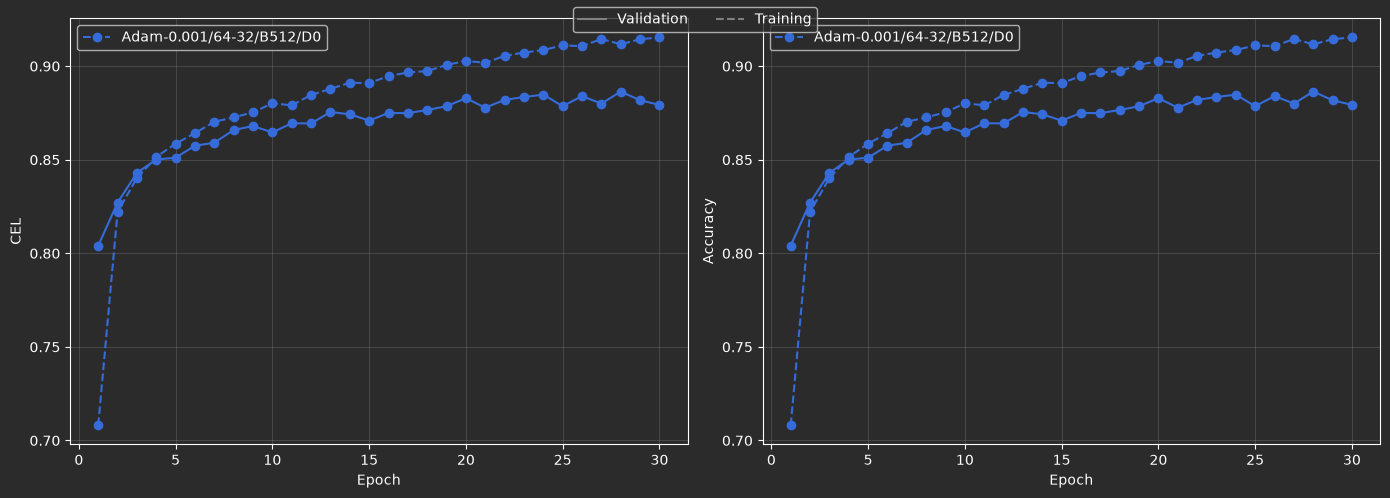

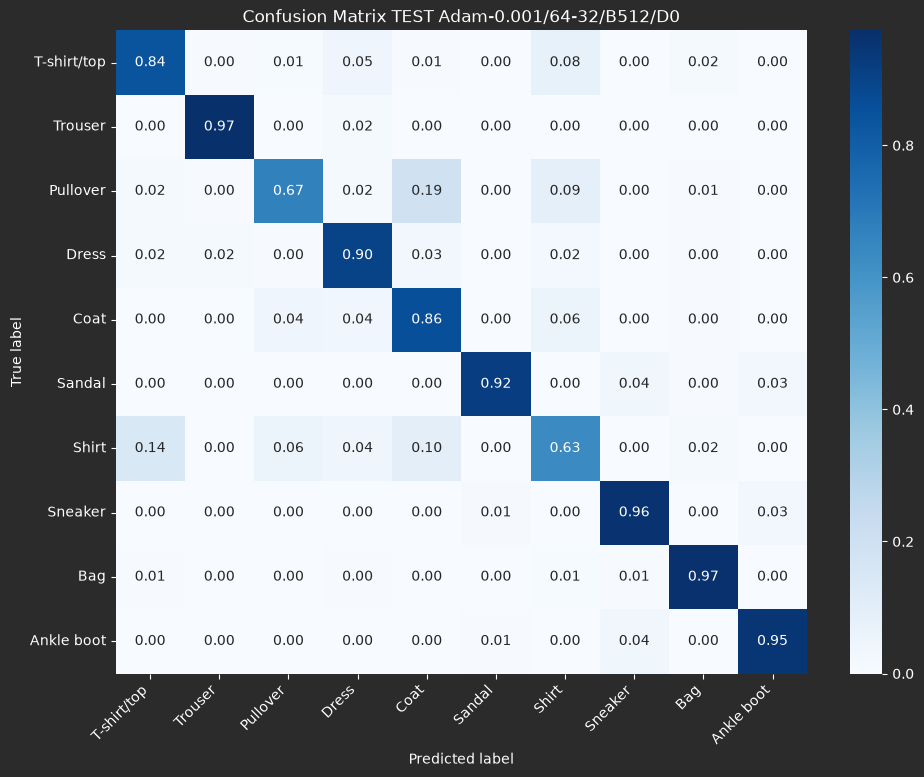

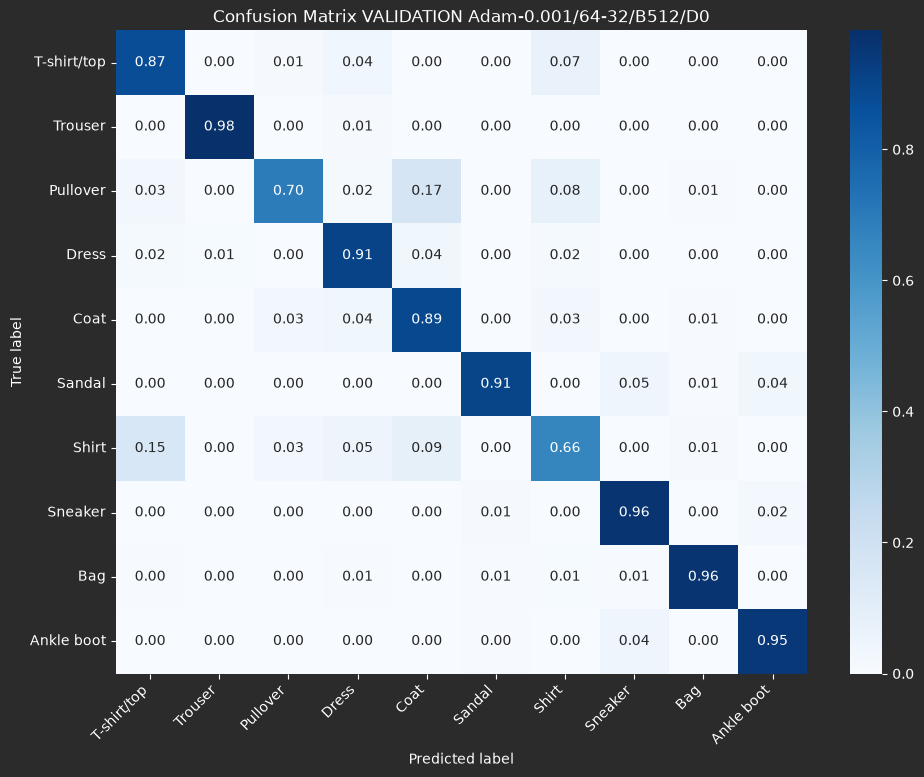


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 512
Training time: 46.16 seconds

Peak GPU memory: 20.67 MB

Test CEL: 0.36074
Test accuracy: 87.37%

----------------- Adam-0.001/64-32/B512/D0.2 -----------------


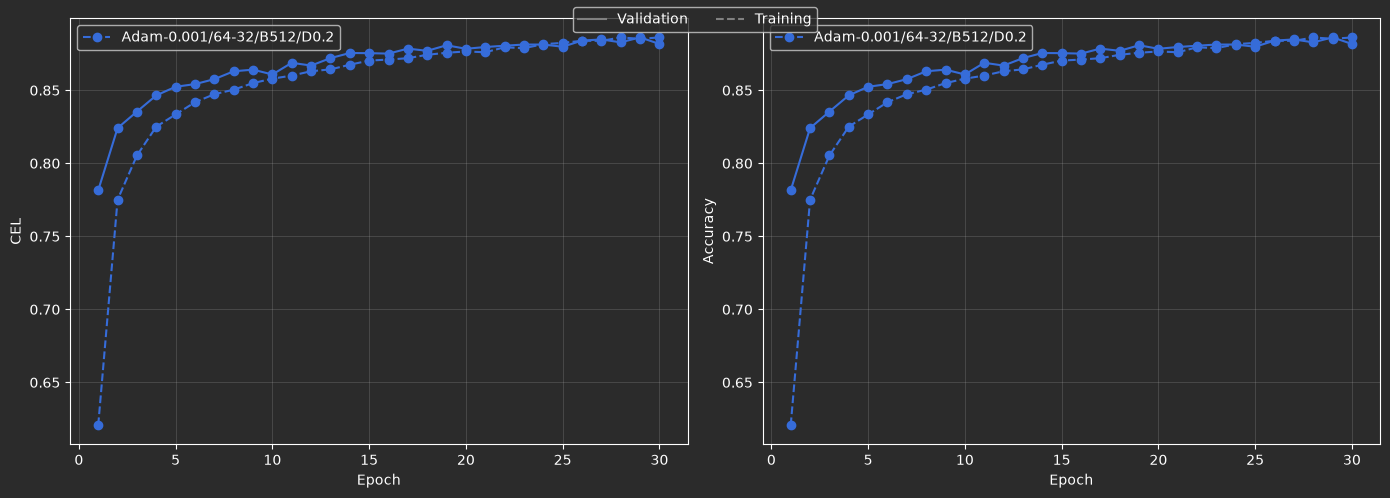

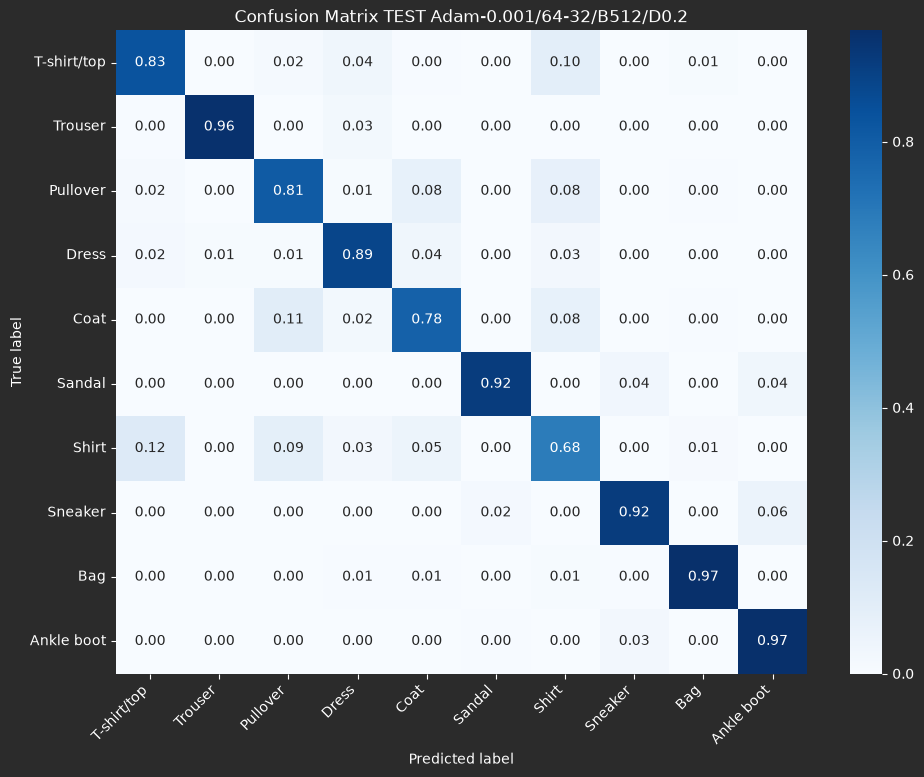

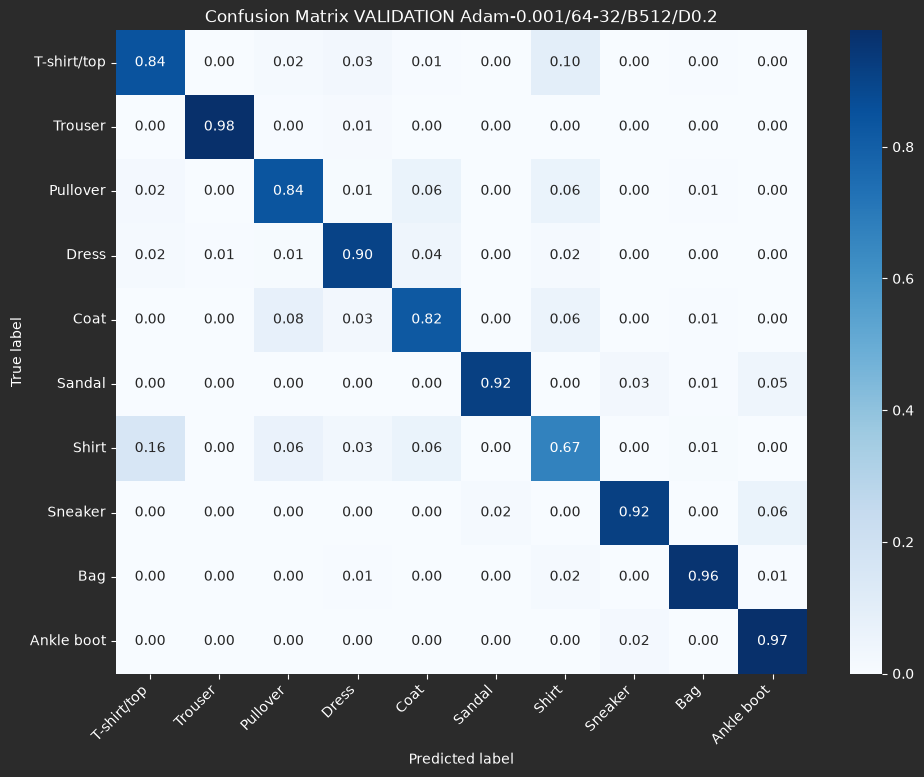


Optimizador: Adam
Dropout: 0.5

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.5 | Batch size -> 512
Training time: 46.08 seconds

Peak GPU memory: 21.48 MB

Test CEL: 0.41533
Test accuracy: 84.97%

----------------- Adam-0.001/64-32/B512/D0.5 -----------------


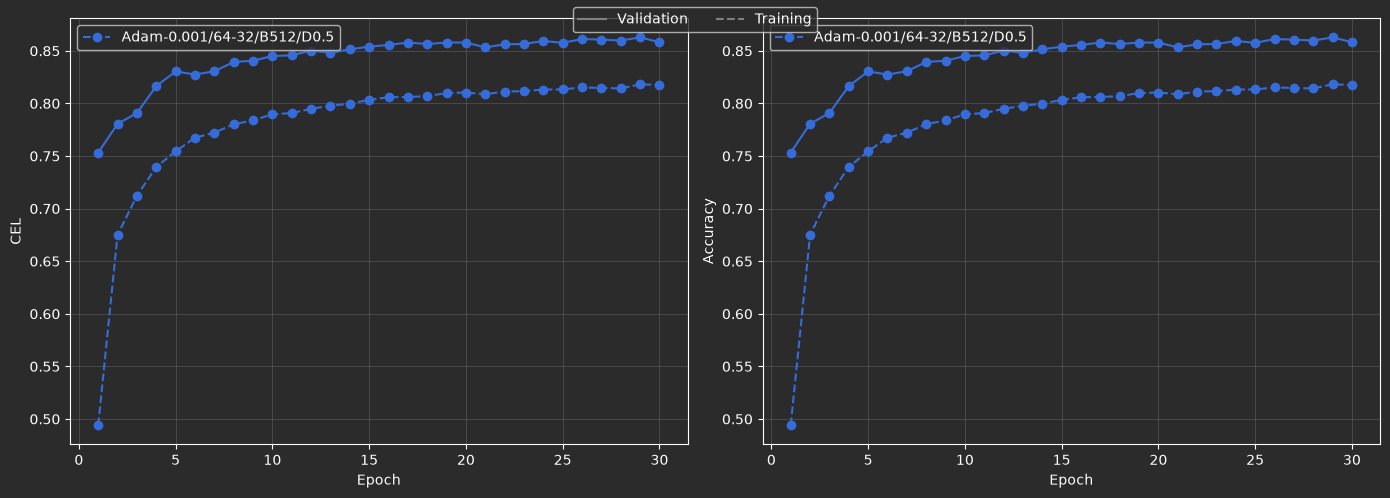

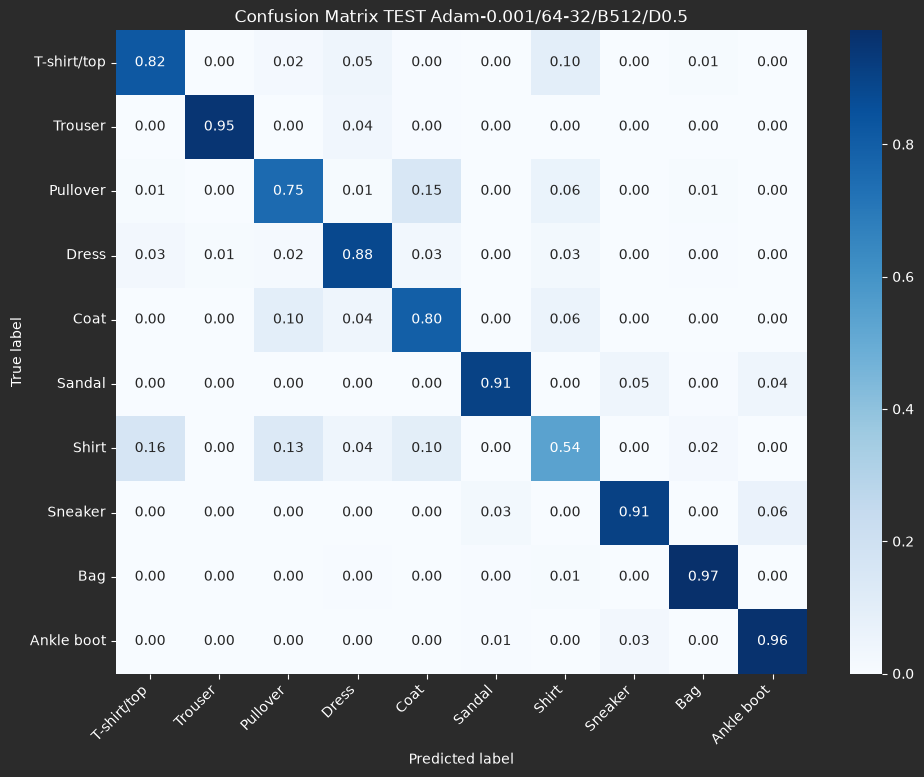

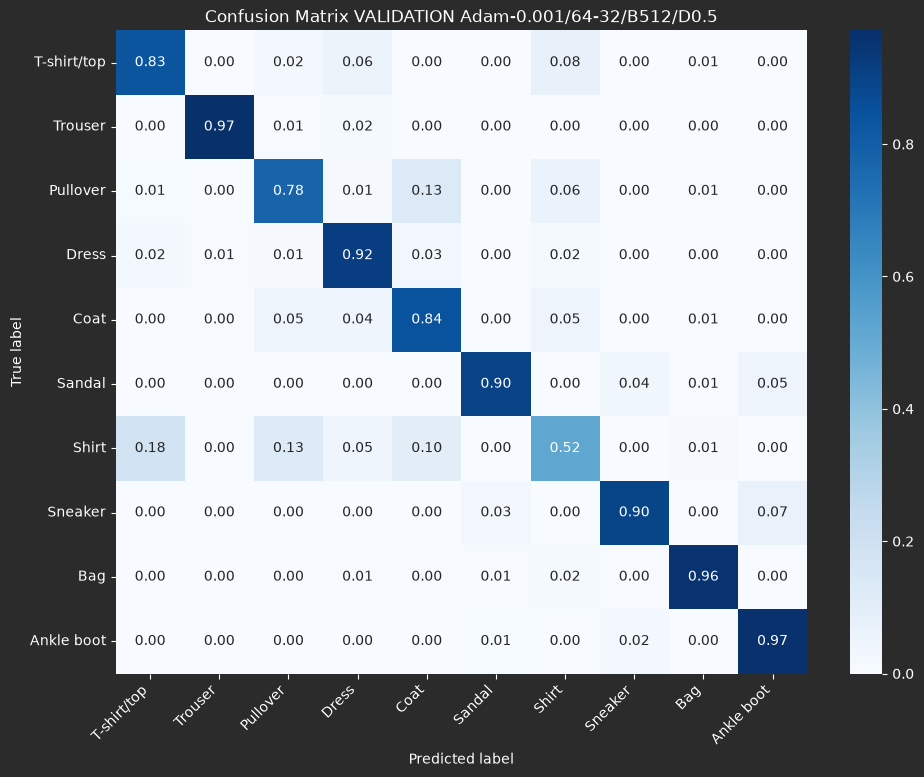


Optimizador: Adam
Dropout: 0

Iniciando entrenamiento... Opti -> Adam | Drop -> 0 | Batch size -> 512
Training time: 46.19 seconds

Peak GPU memory: 22.88 MB

Test CEL: 0.35324
Test accuracy: 87.89%

----------------- Adam-0.001/128-64/B512/D0 -----------------


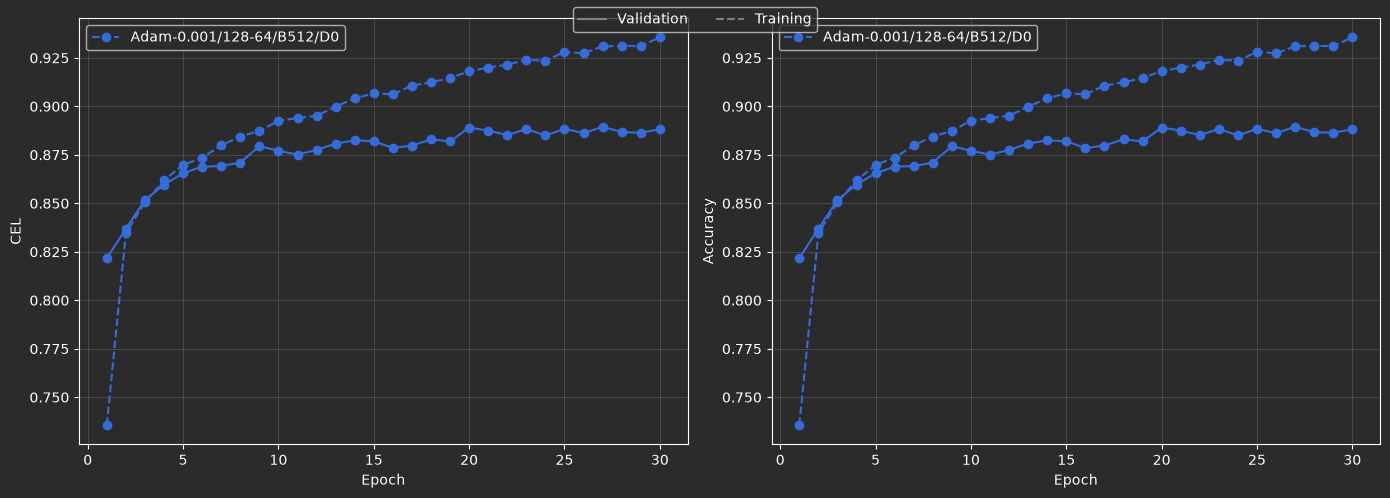

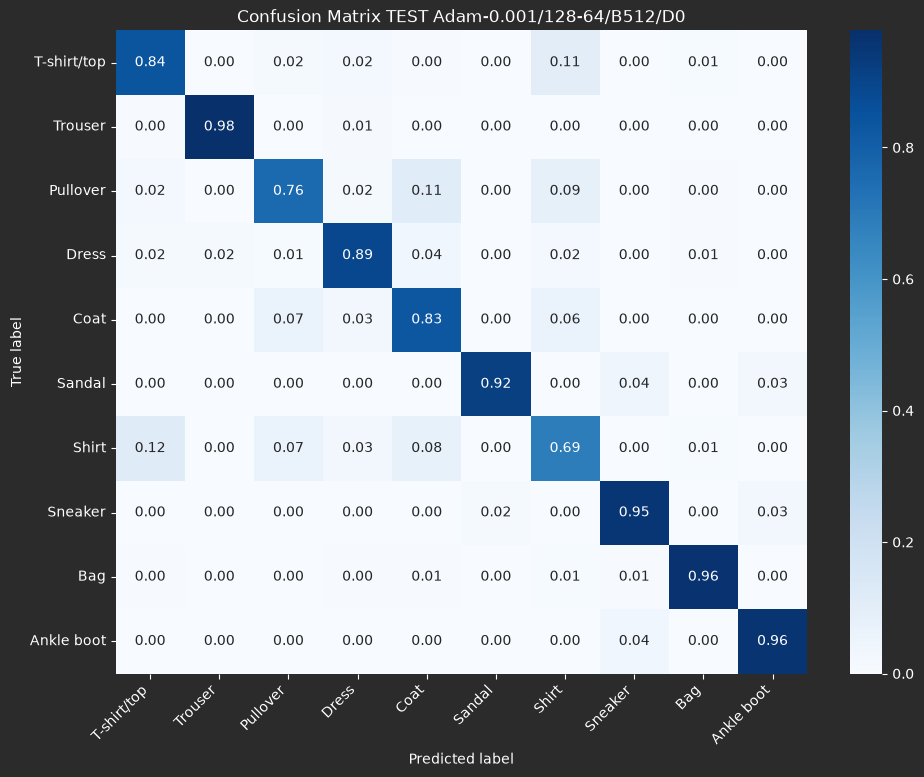

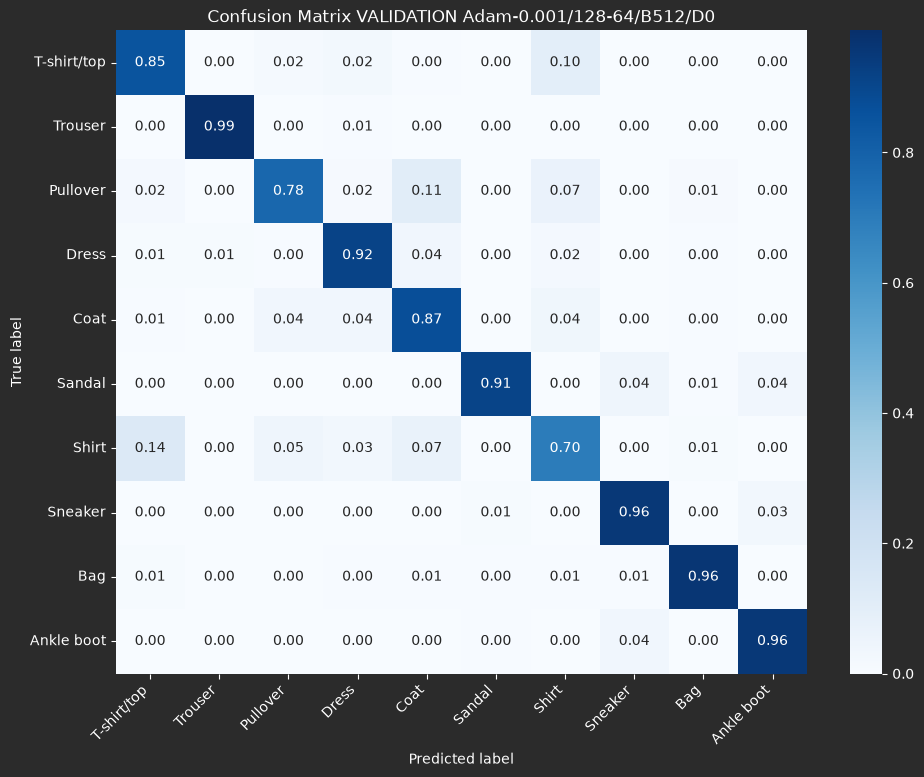


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 512
Training time: 46.10 seconds

Peak GPU memory: 25.02 MB

Test CEL: 0.32855
Test accuracy: 88.60%

----------------- Adam-0.001/128-64/B512/D0.2 -----------------


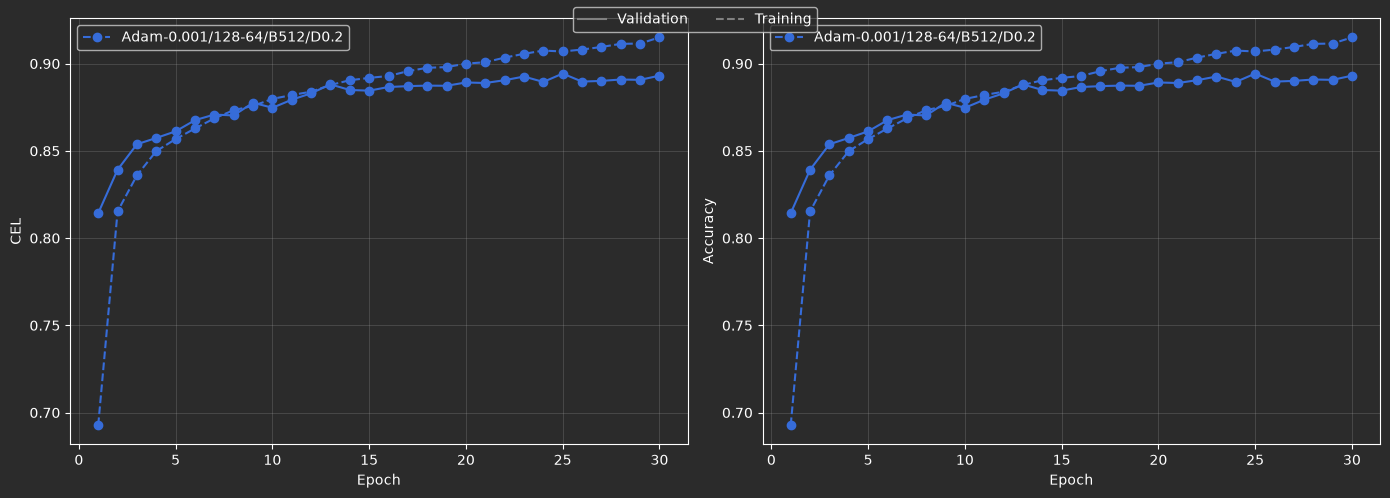

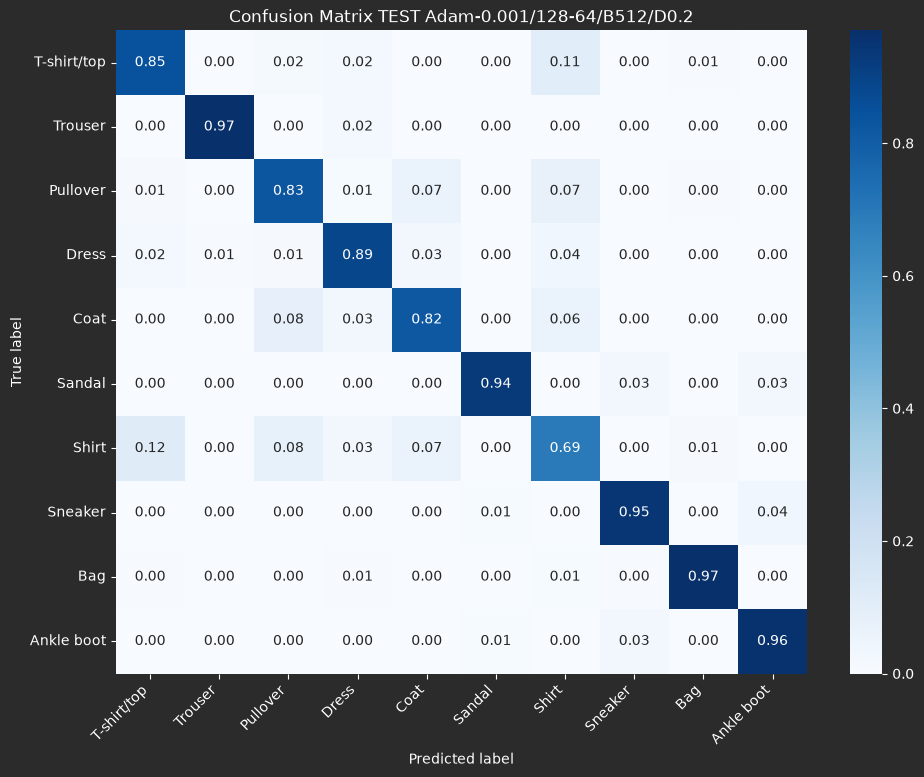

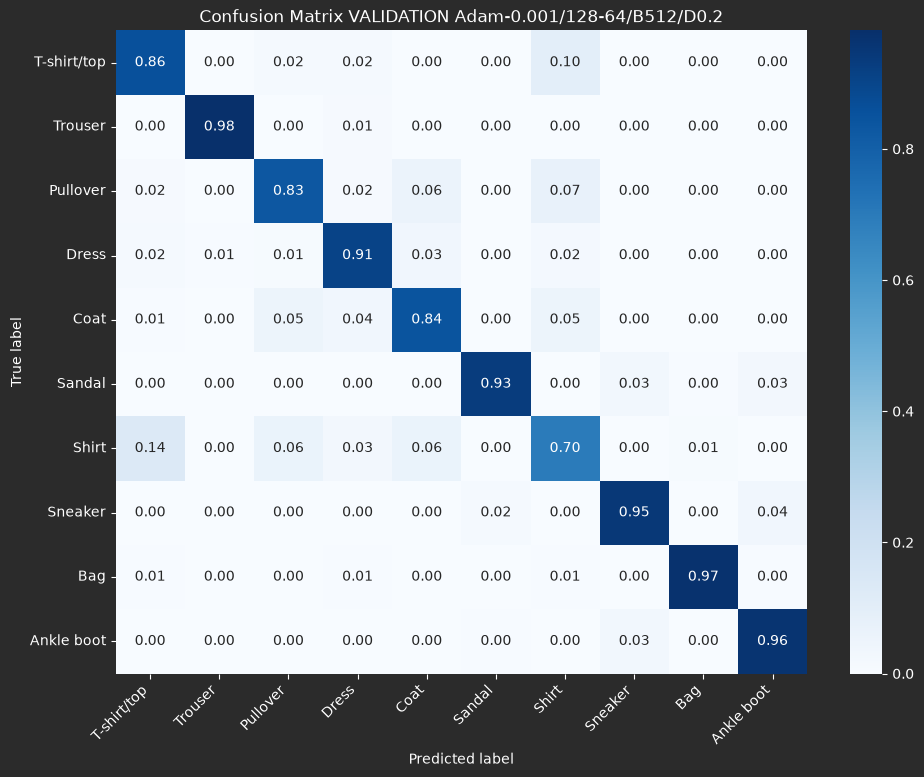


Optimizador: Adam
Dropout: 0.5

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.5 | Batch size -> 512
Training time: 45.60 seconds

Peak GPU memory: 26.70 MB

Test CEL: 0.36536
Test accuracy: 87.04%

----------------- Adam-0.001/128-64/B512/D0.5 -----------------


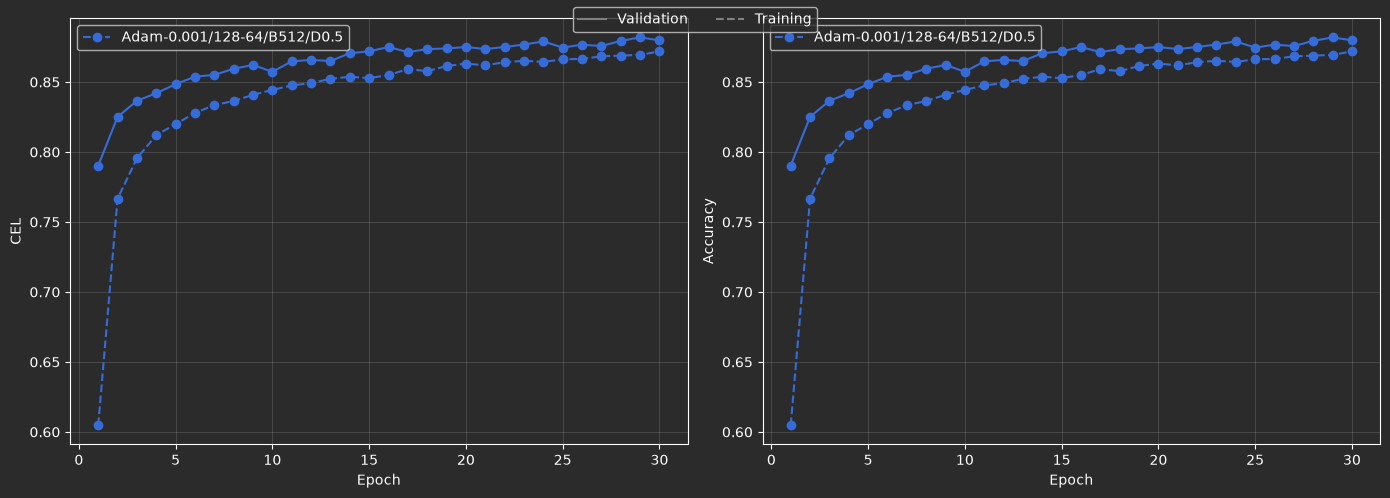

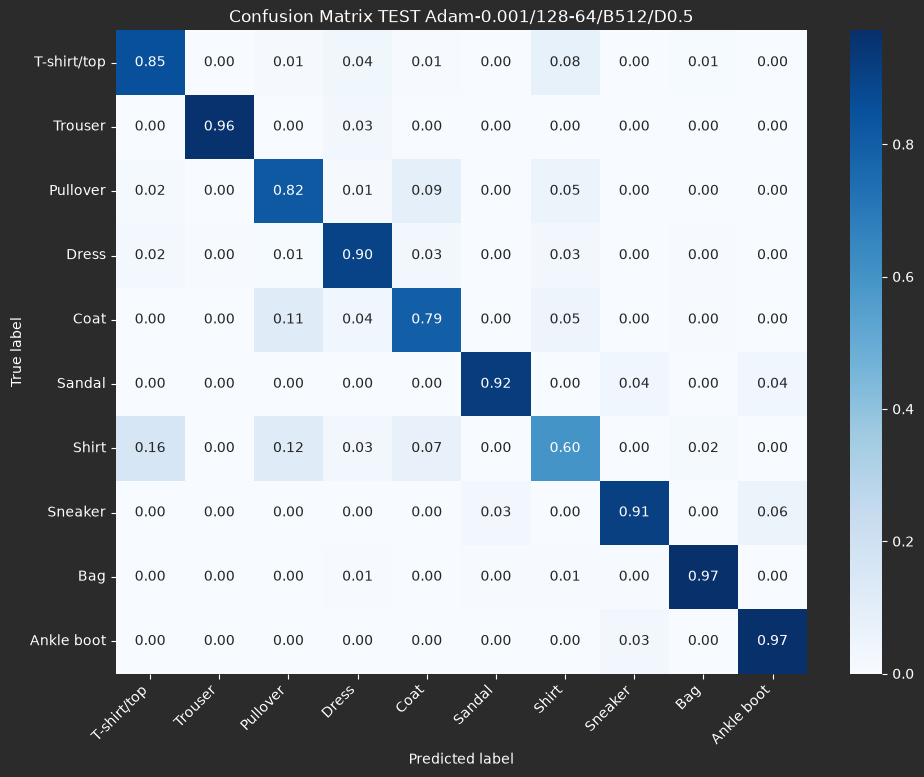

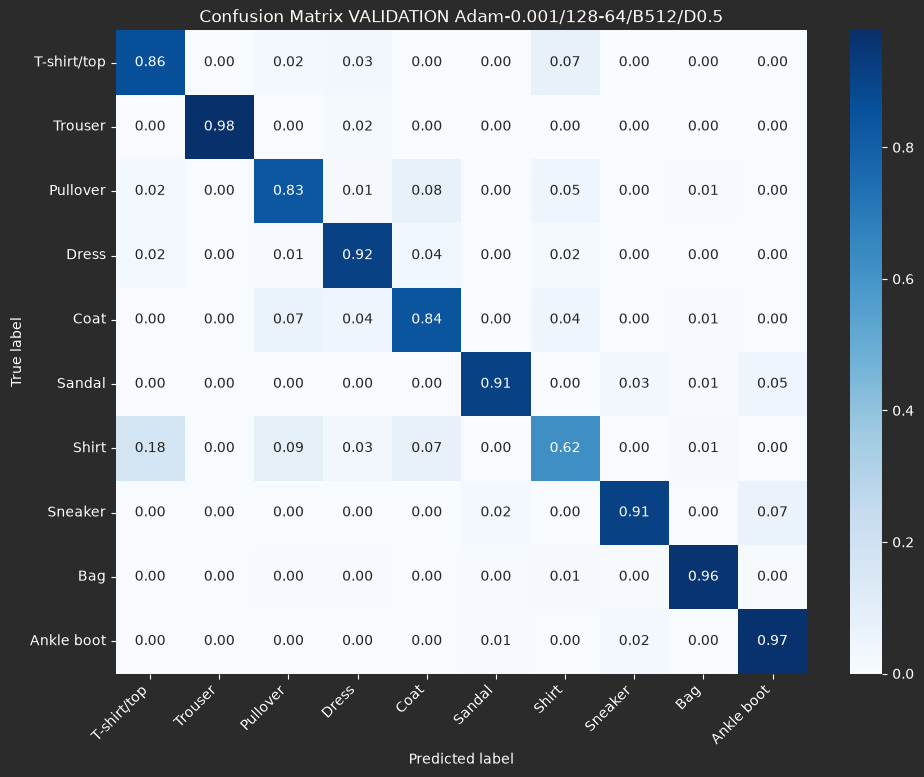


Optimizador: Adam
Dropout: 0

Iniciando entrenamiento... Opti -> Adam | Drop -> 0 | Batch size -> 512
Training time: 45.56 seconds

Peak GPU memory: 29.74 MB

Test CEL: 0.38028
Test accuracy: 88.67%

----------------- Adam-0.001/256-128/B512/D0 -----------------


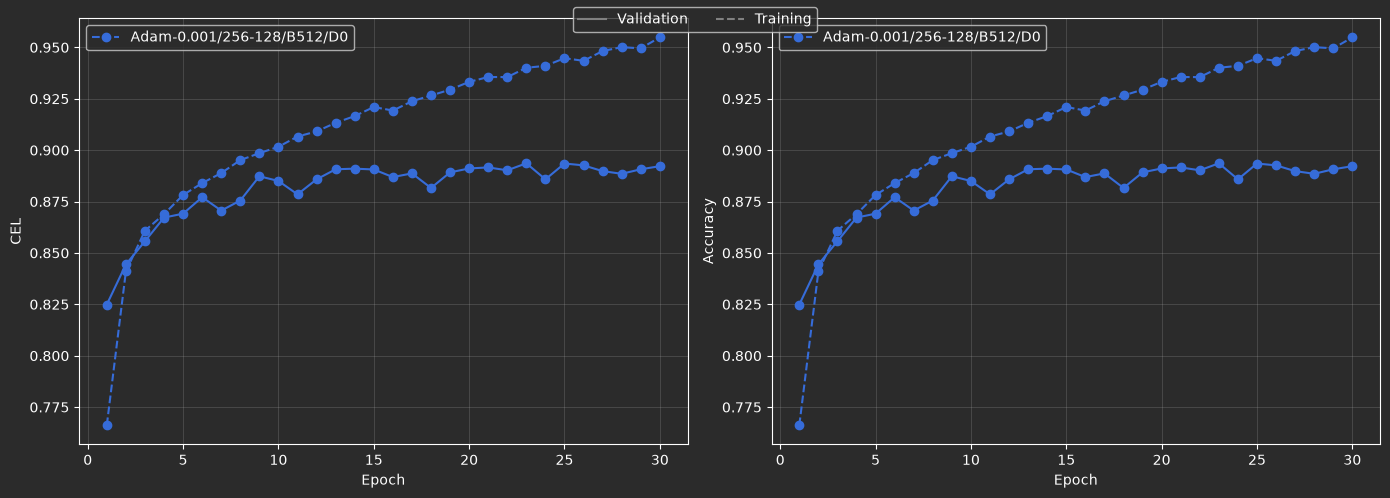

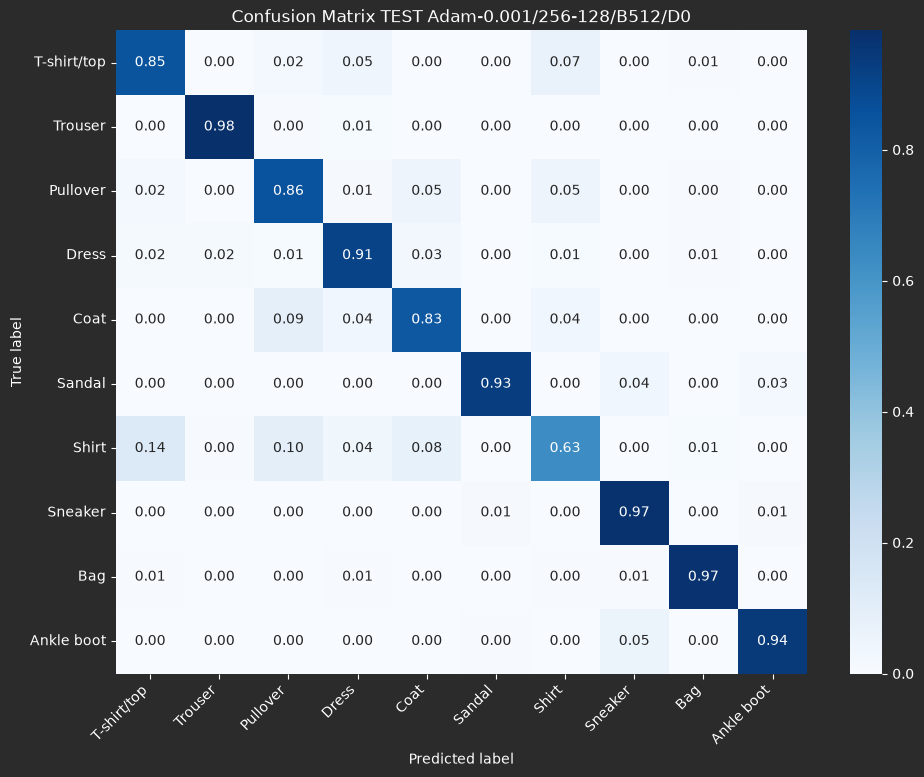

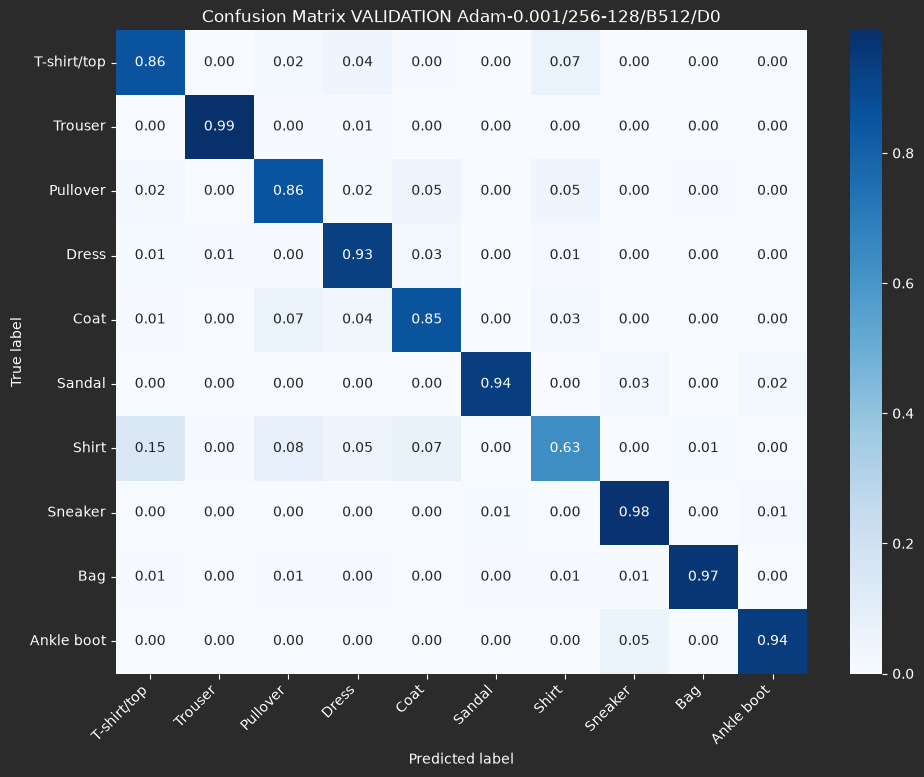


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 512
Training time: 45.52 seconds

Peak GPU memory: 34.24 MB

Test CEL: 0.32908
Test accuracy: 89.15%

----------------- Adam-0.001/256-128/B512/D0.2 -----------------


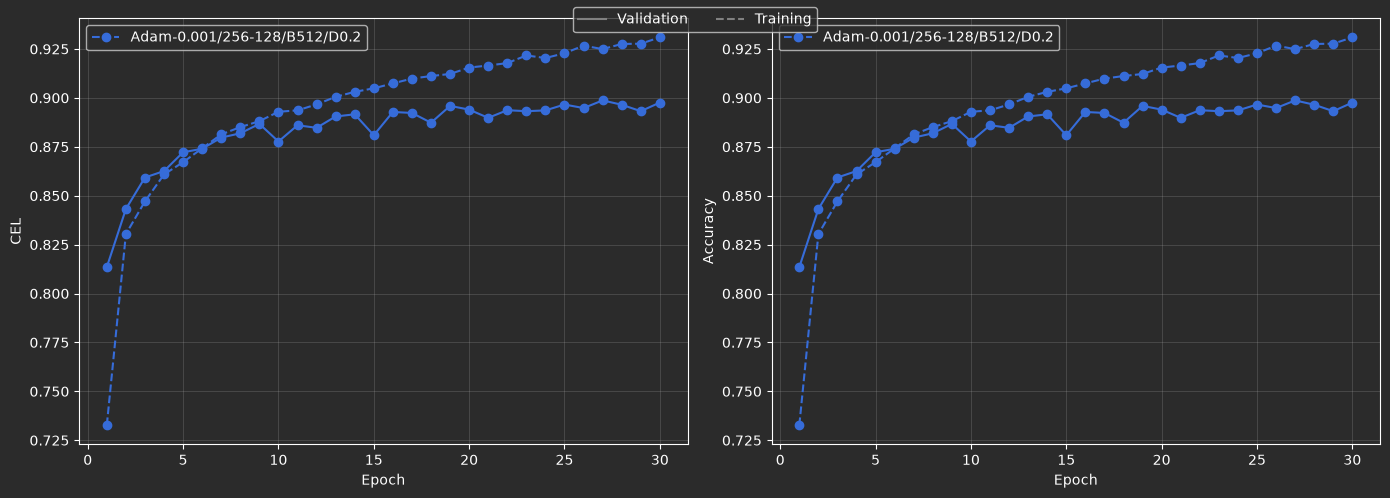

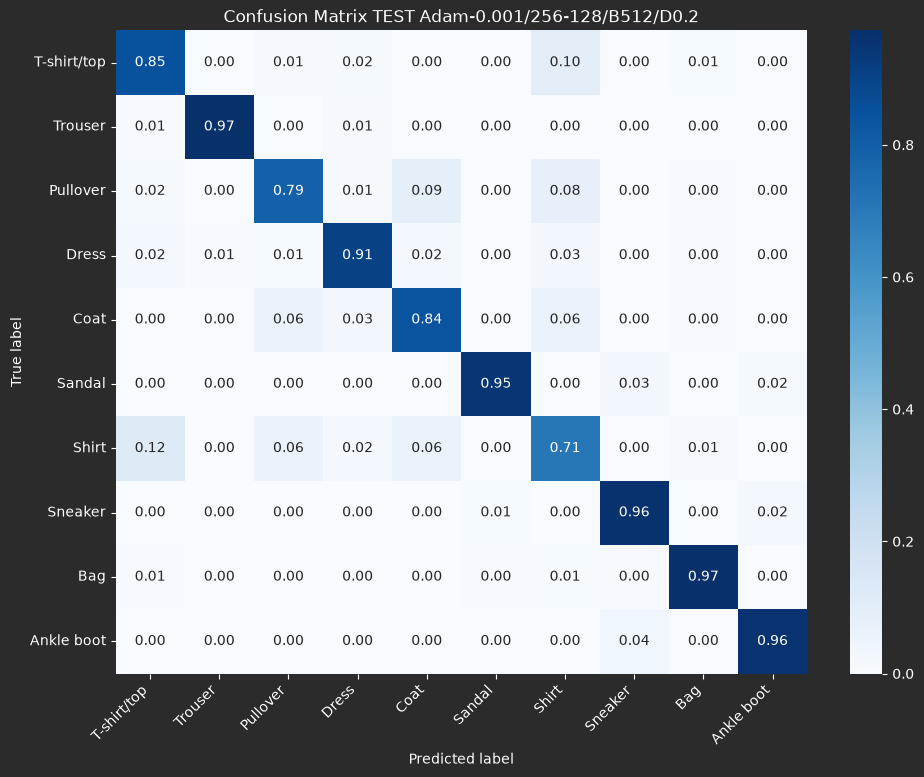

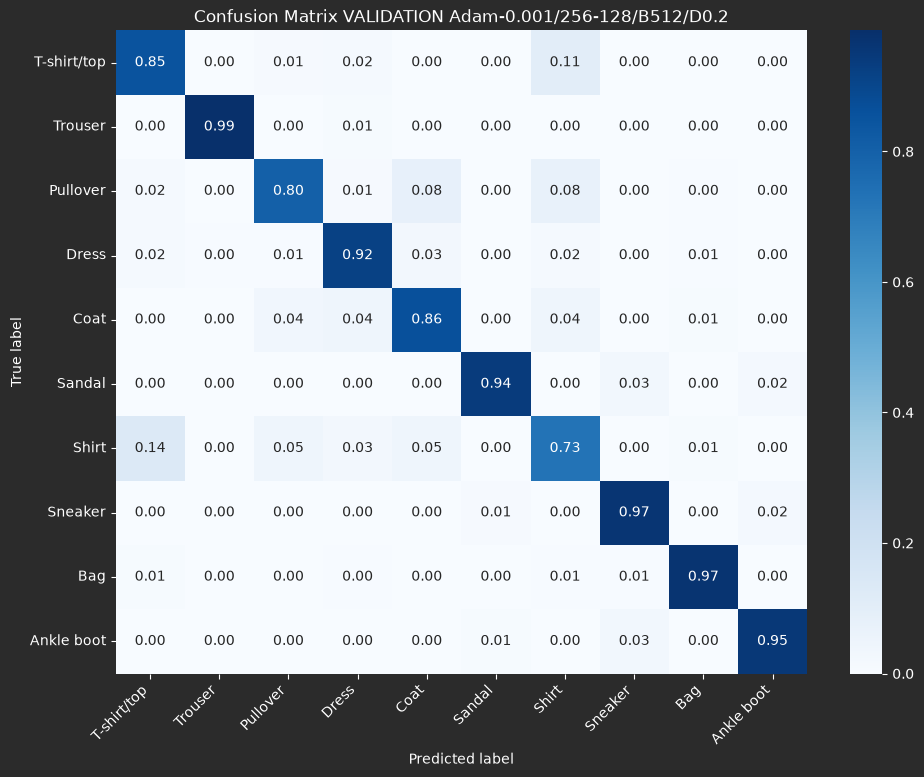


Optimizador: Adam
Dropout: 0.5

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.5 | Batch size -> 512
Training time: 45.54 seconds

Peak GPU memory: 37.83 MB

Test CEL: 0.33063
Test accuracy: 88.15%

----------------- Adam-0.001/256-128/B512/D0.5 -----------------


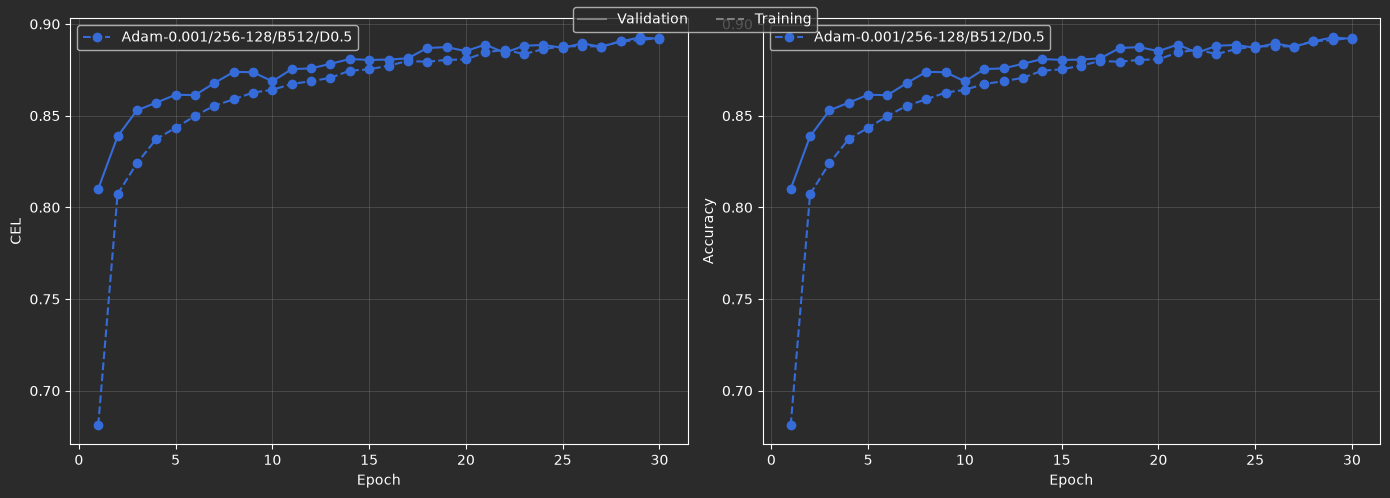

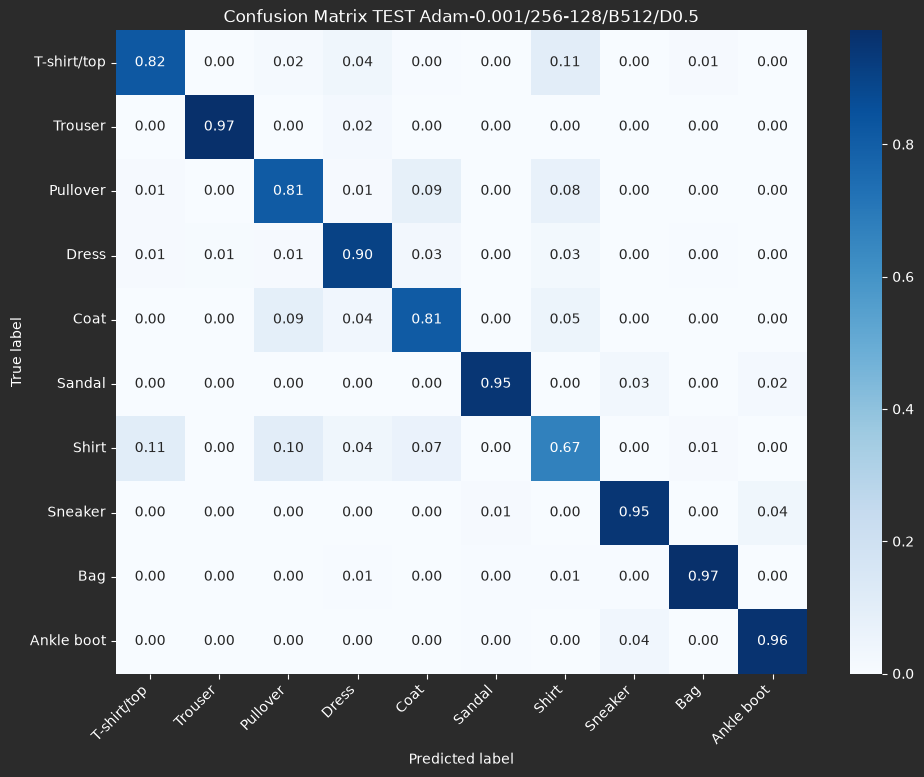

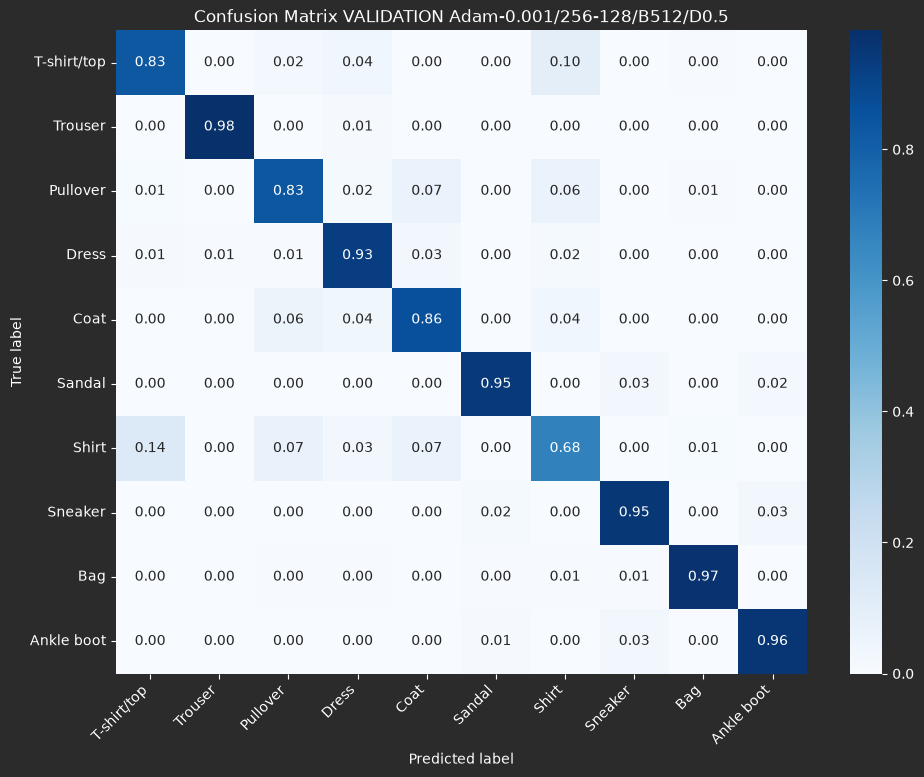


Optimizador: Adam
Dropout: 0

Iniciando entrenamiento... Opti -> Adam | Drop -> 0 | Batch size -> 512
Training time: 45.17 seconds

Peak GPU memory: 46.93 MB

Test CEL: 0.44156
Test accuracy: 88.89%

----------------- Adam-0.001/512-256/B512/D0 -----------------


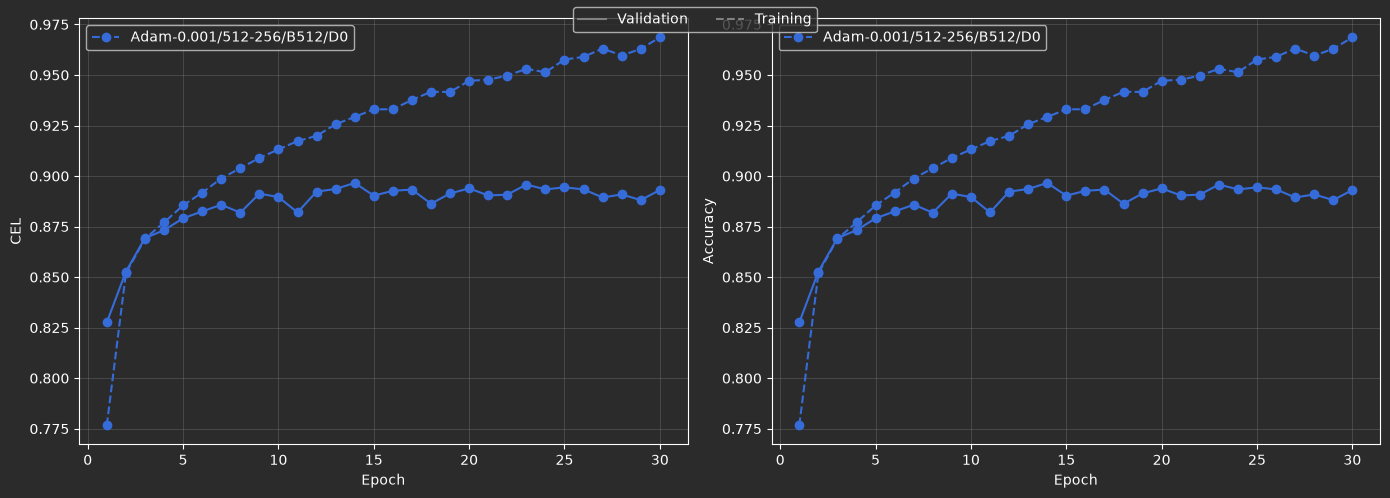

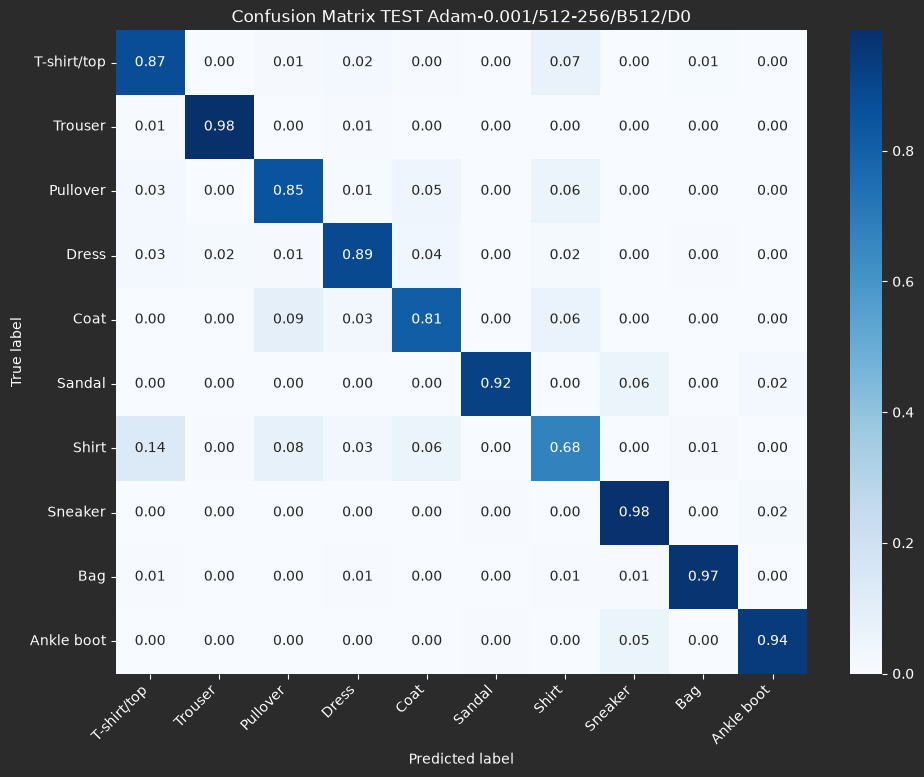

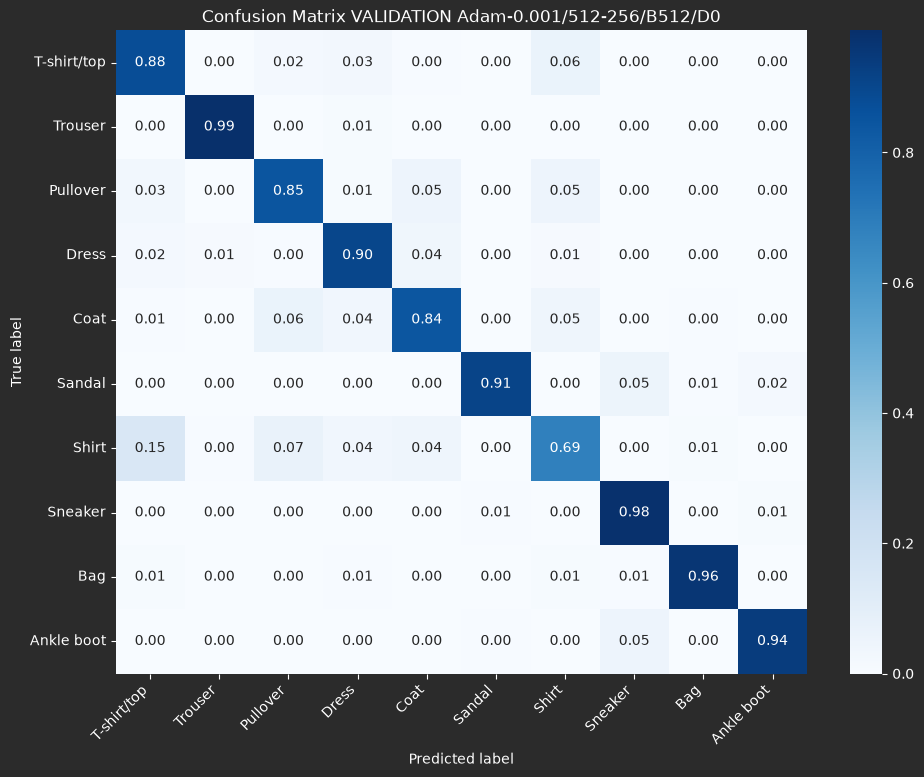


Optimizador: Adam
Dropout: 0.2

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.2 | Batch size -> 512
Training time: 45.85 seconds

Peak GPU memory: 55.41 MB

Test CEL: 0.34537
Test accuracy: 89.12%

----------------- Adam-0.001/512-256/B512/D0.2 -----------------


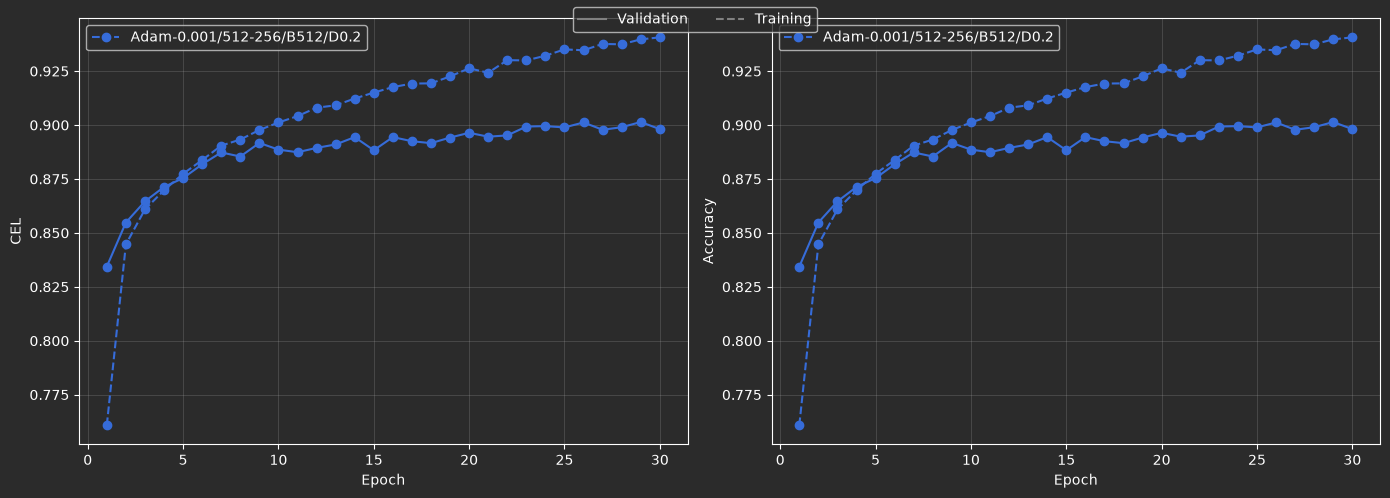

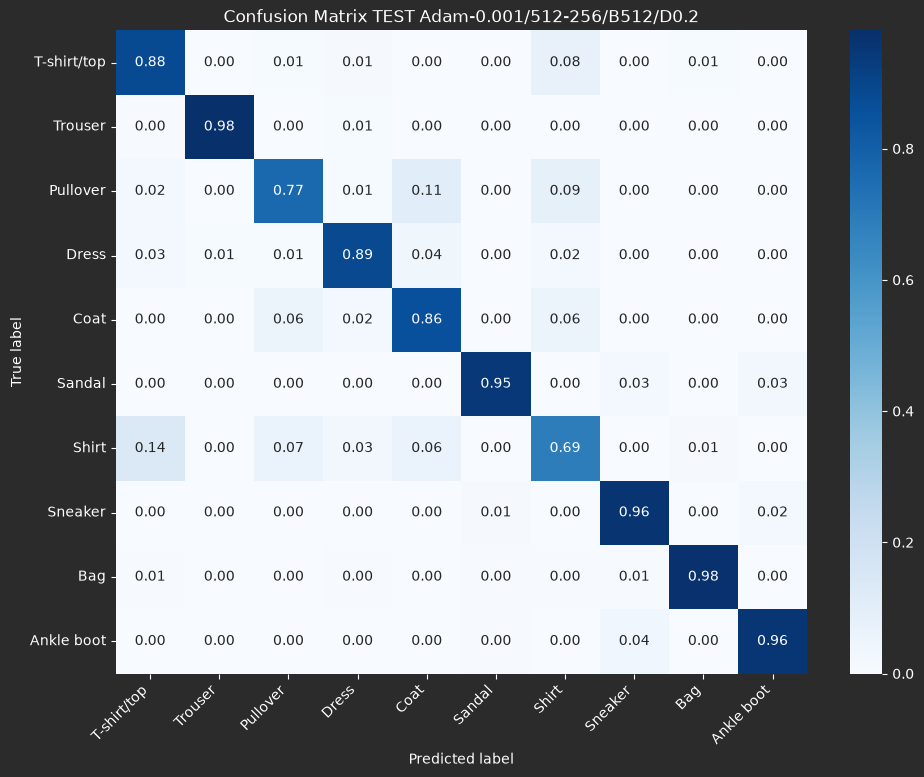

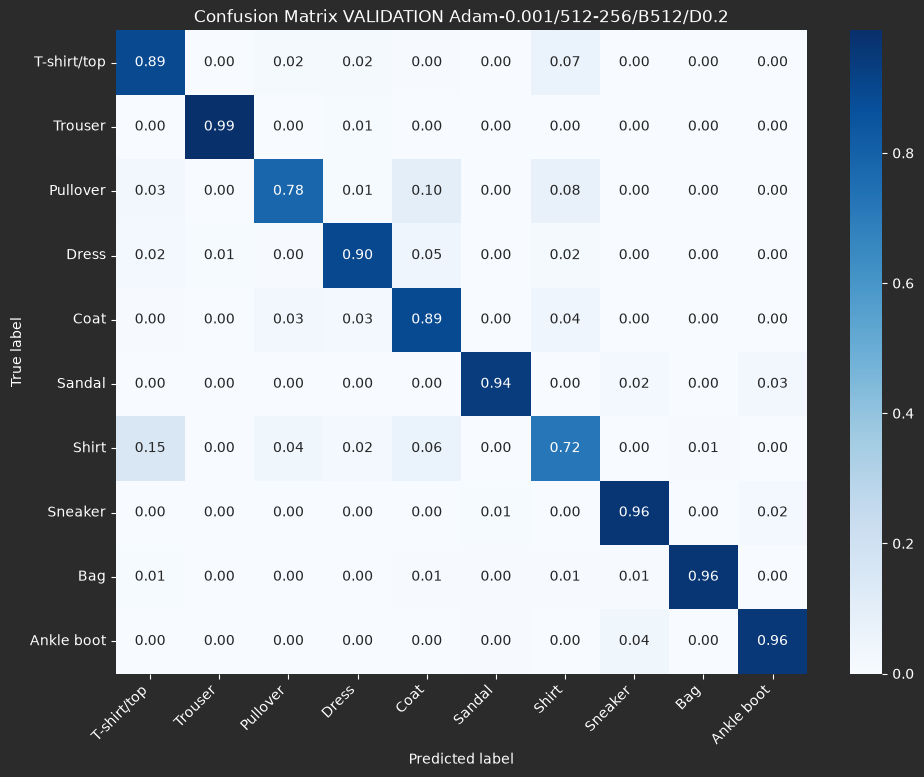


Optimizador: Adam
Dropout: 0.5

Iniciando entrenamiento... Opti -> Adam | Drop -> 0.5 | Batch size -> 512
Training time: 45.99 seconds

Peak GPU memory: 63.59 MB

Test CEL: 0.32069
Test accuracy: 88.88%

----------------- Adam-0.001/512-256/B512/D0.5 -----------------


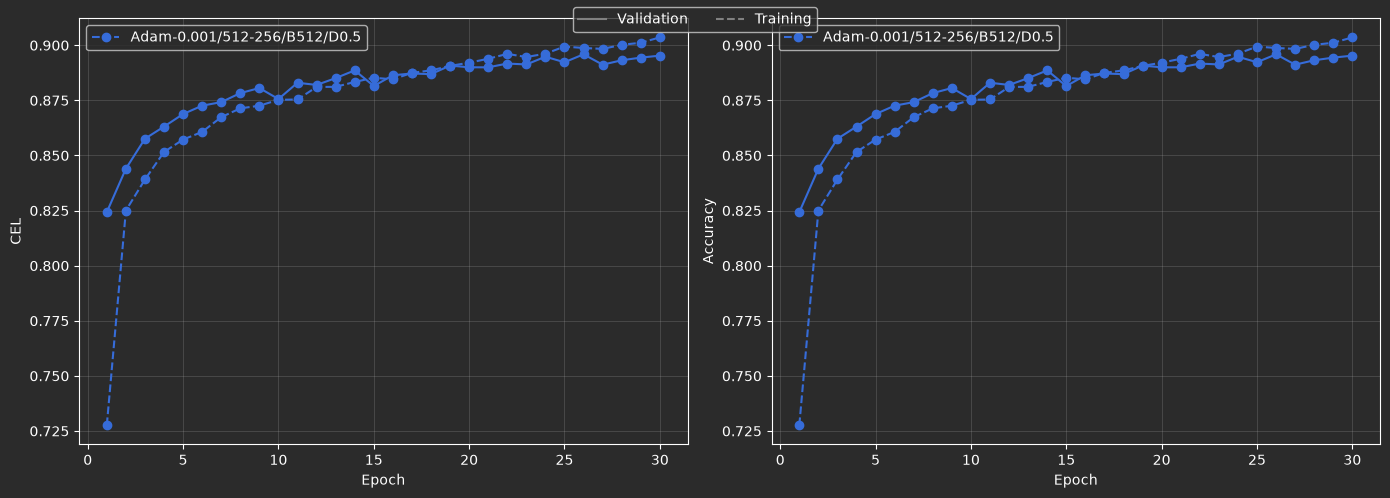

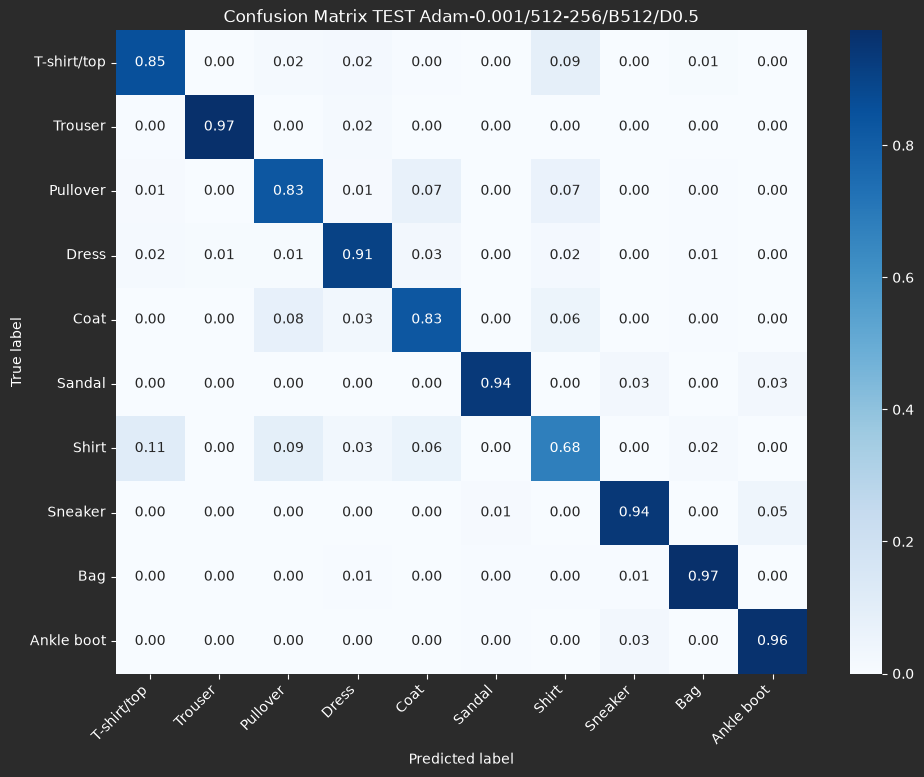

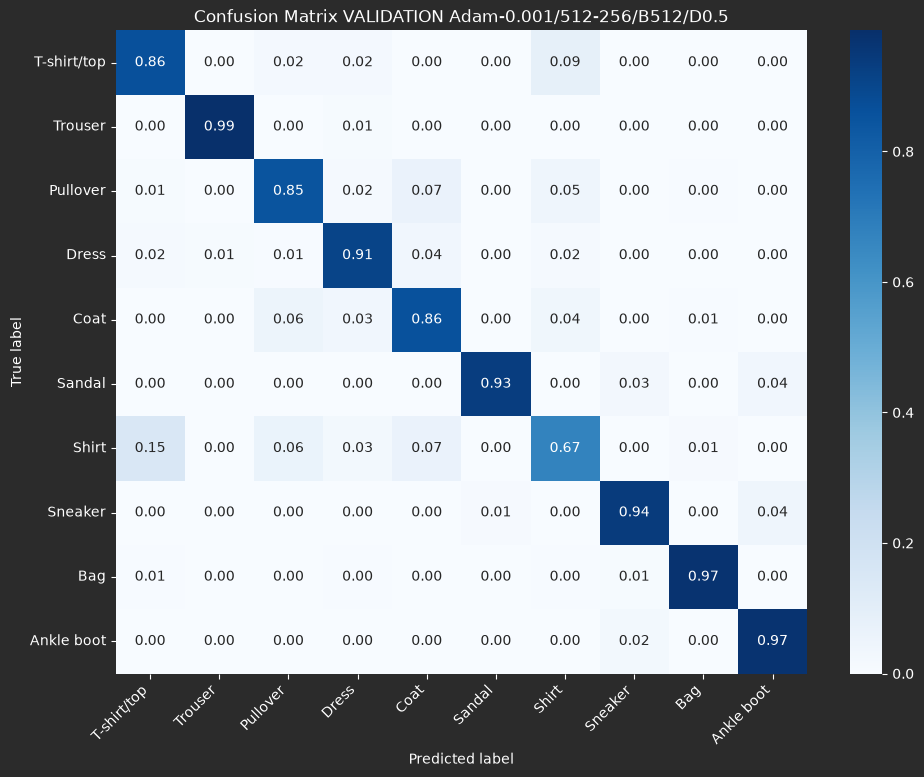

In [2]:
aftermath = pre_run(expies, data_loaders)


-----------------------------------Results TOGETHER:-----------------------------------


-----------------------------------GROUP: (0,):-----------------------------------

----------------- Adam-0.001/64-32/B512/D0 -----------------
----------------- Adam-0.001/128-64/B512/D0 -----------------
----------------- Adam-0.001/256-128/B512/D0 -----------------
----------------- Adam-0.001/512-256/B512/D0 -----------------


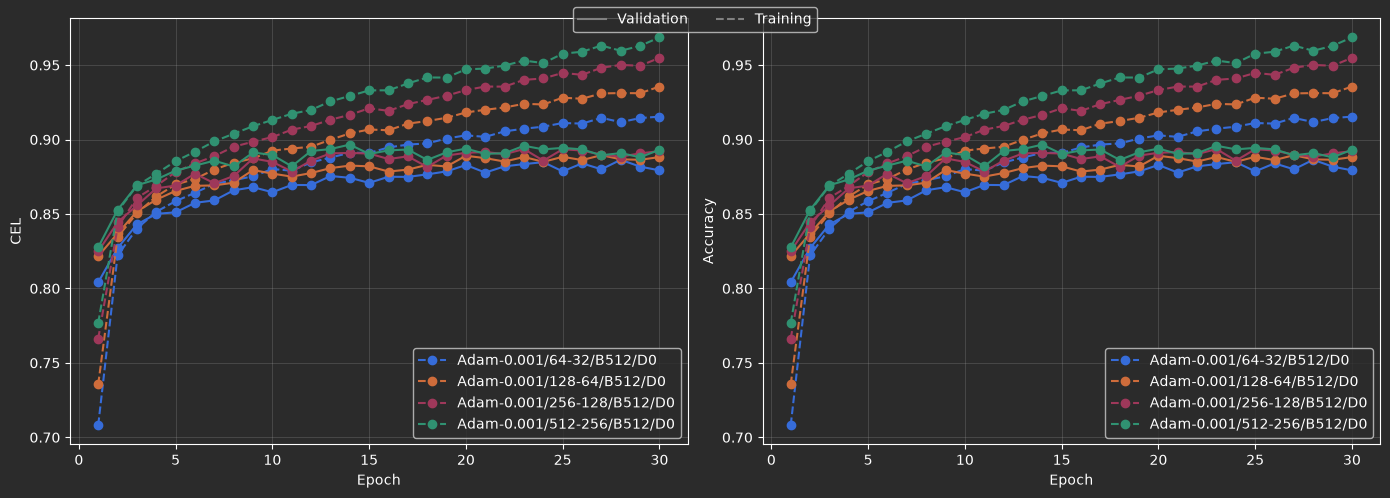

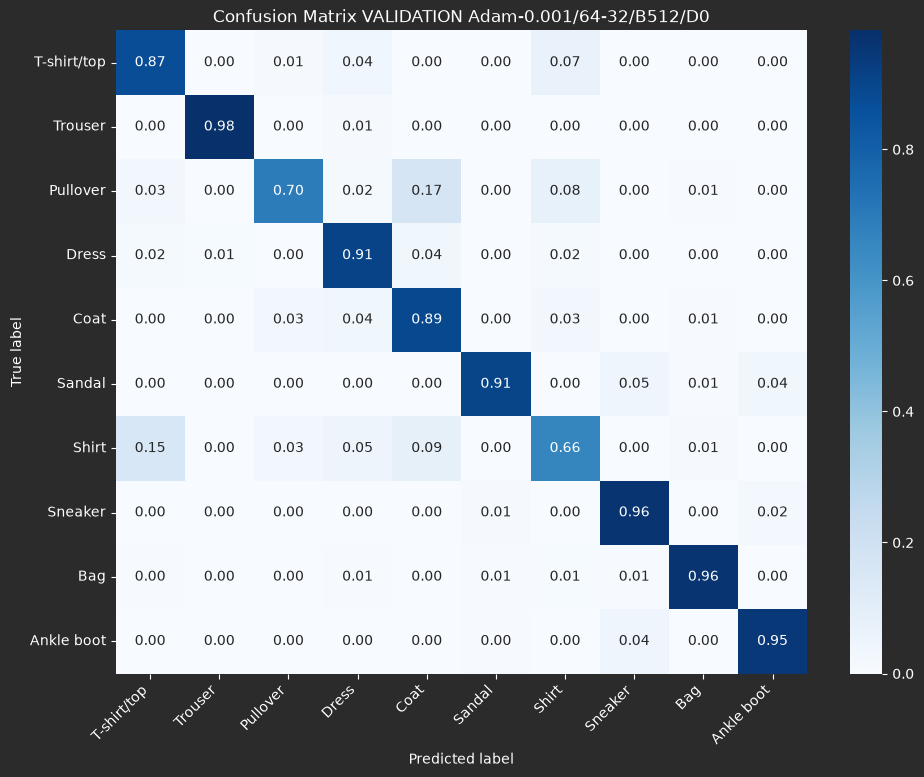

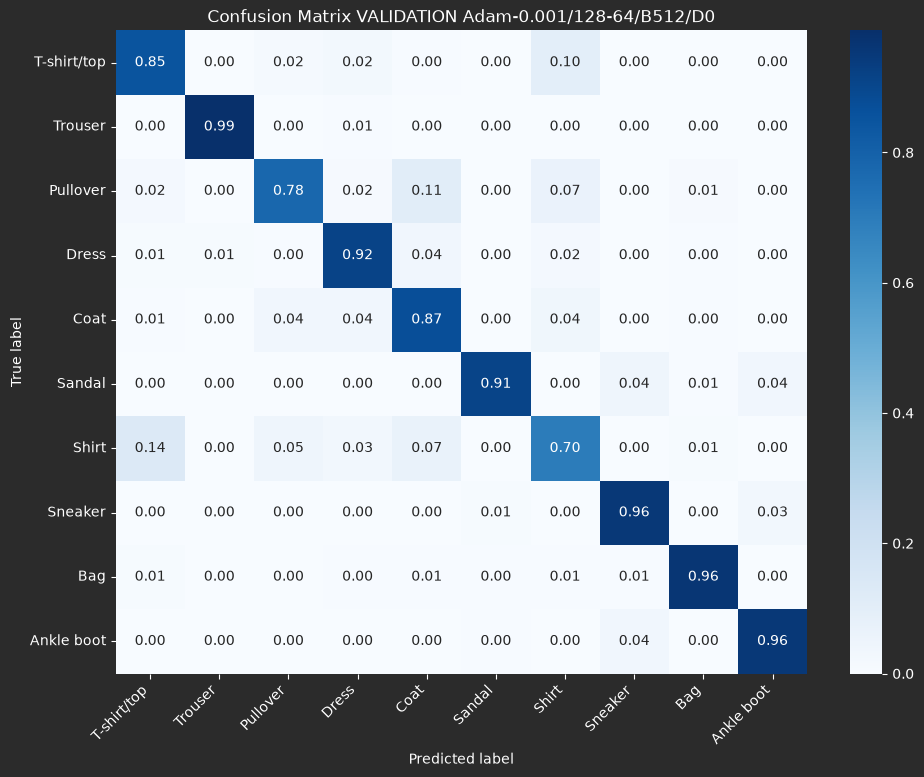

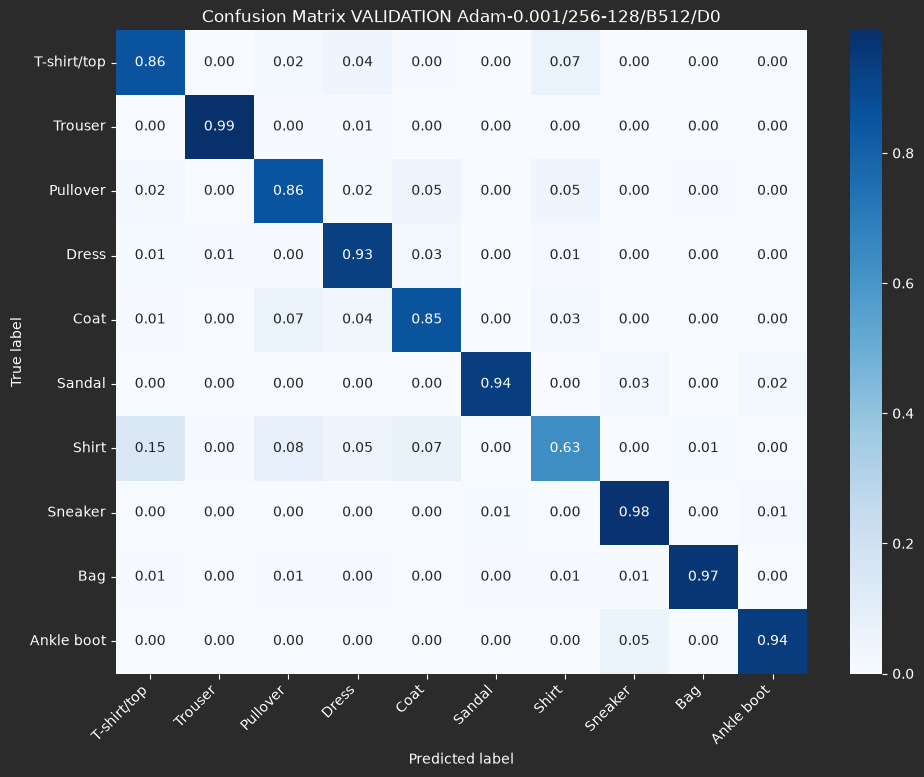

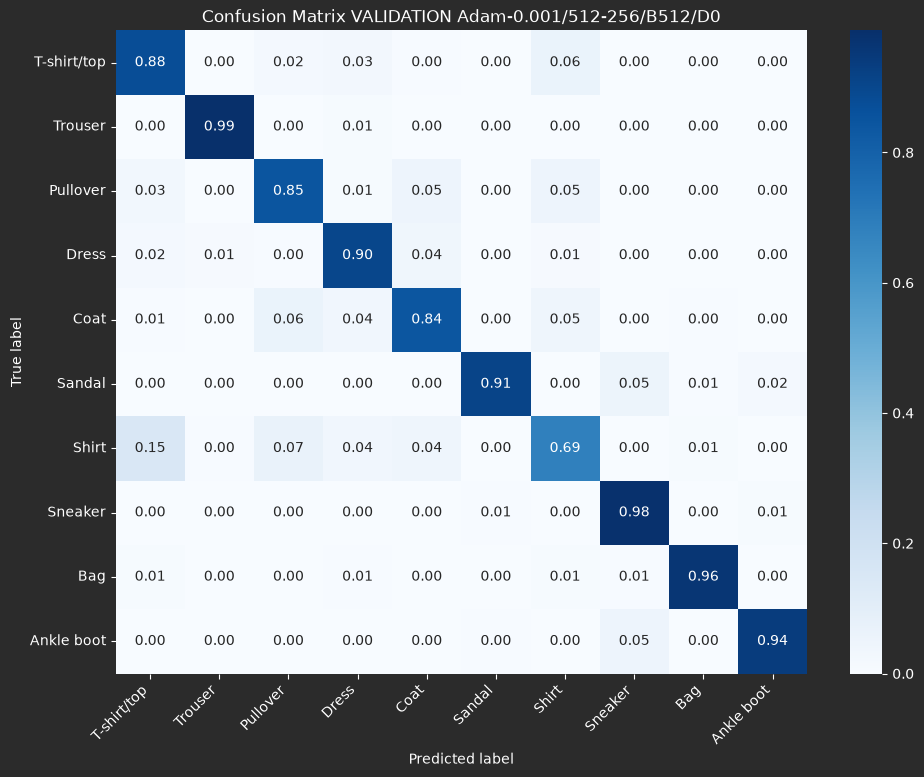

                           Train Loss Valid Loss Train Accu Valid Accu Test Accu Test Worst Class (Recall) Valid Worst Class (Recall) Test Worst Recall Value Valid Worst Recall Value TV gap Test CM Deviation Valid CM Deviation
Adam-0.001/64-32/B512/D0        0.229      0.349      0.915      0.879     0.868            Shirt (63.40%)             Shirt (66.21%)                   0.634                    0.662  0.036             0.415              0.346
Adam-0.001/128-64/B512/D0       0.177      0.325      0.936      0.888     0.879            Shirt (69.10%)             Shirt (70.18%)                   0.691                    0.702  0.047             0.308              0.265
Adam-0.001/256-128/B512/D0      0.125      0.352      0.955      0.892     0.887            Shirt (63.20%)             Shirt (63.31%)                   0.632                    0.633  0.063             0.297              0.275
Adam-0.001/512-256/B512/D0      0.088      0.401      0.969      0.893     0.889            

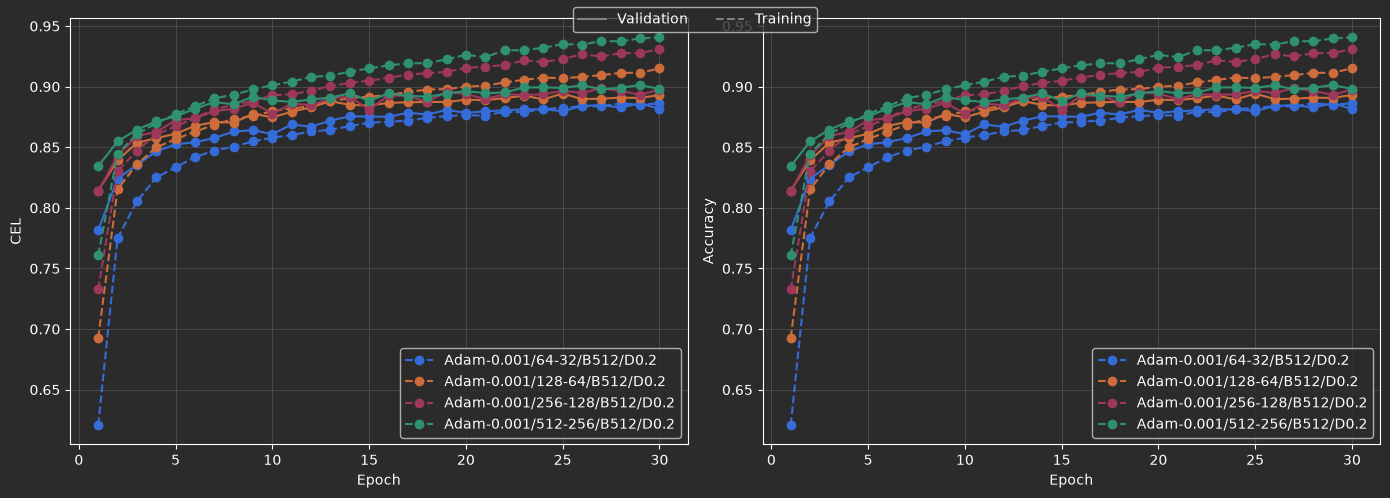

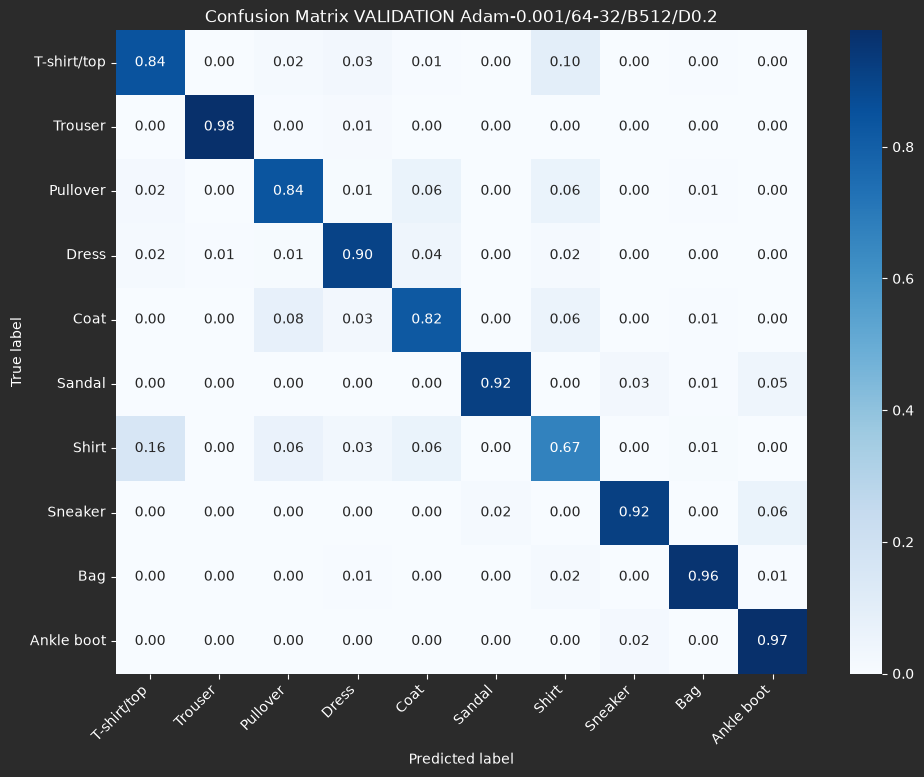

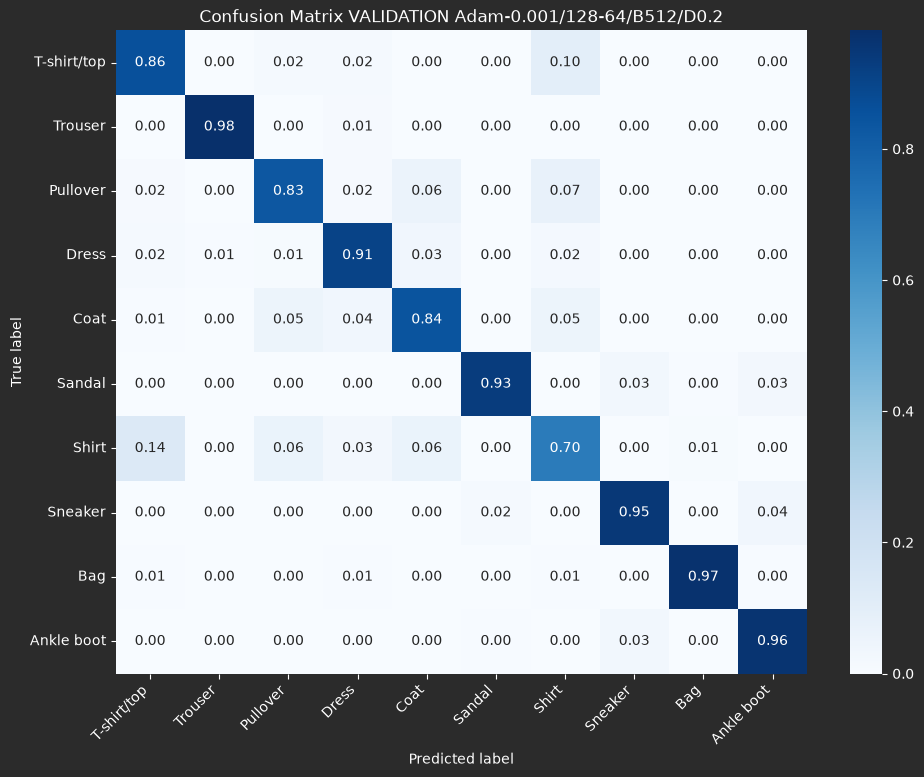

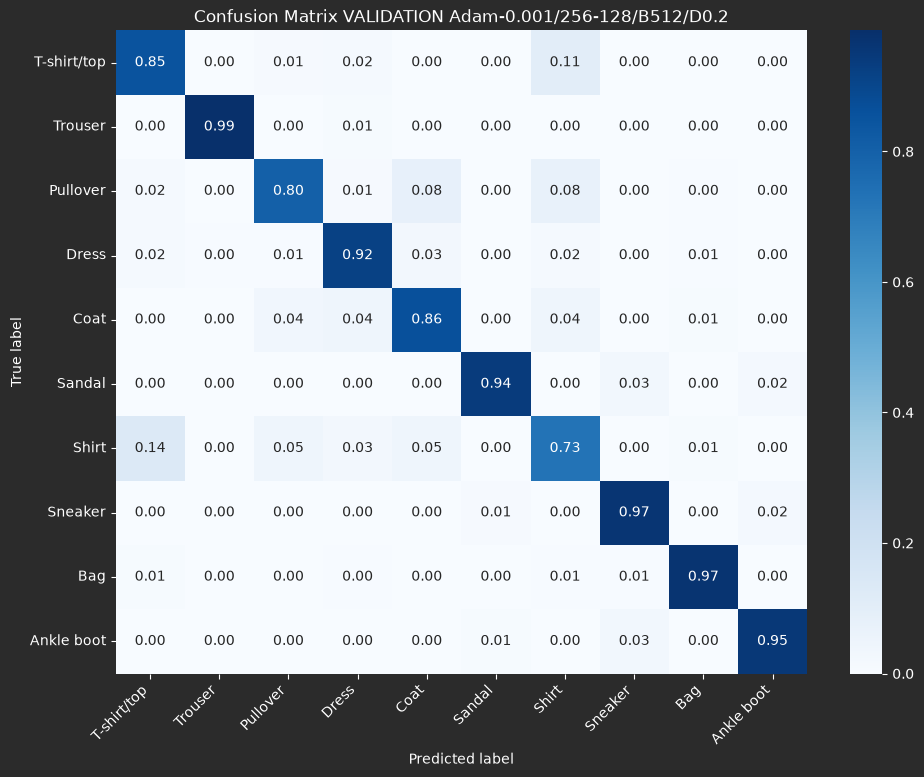

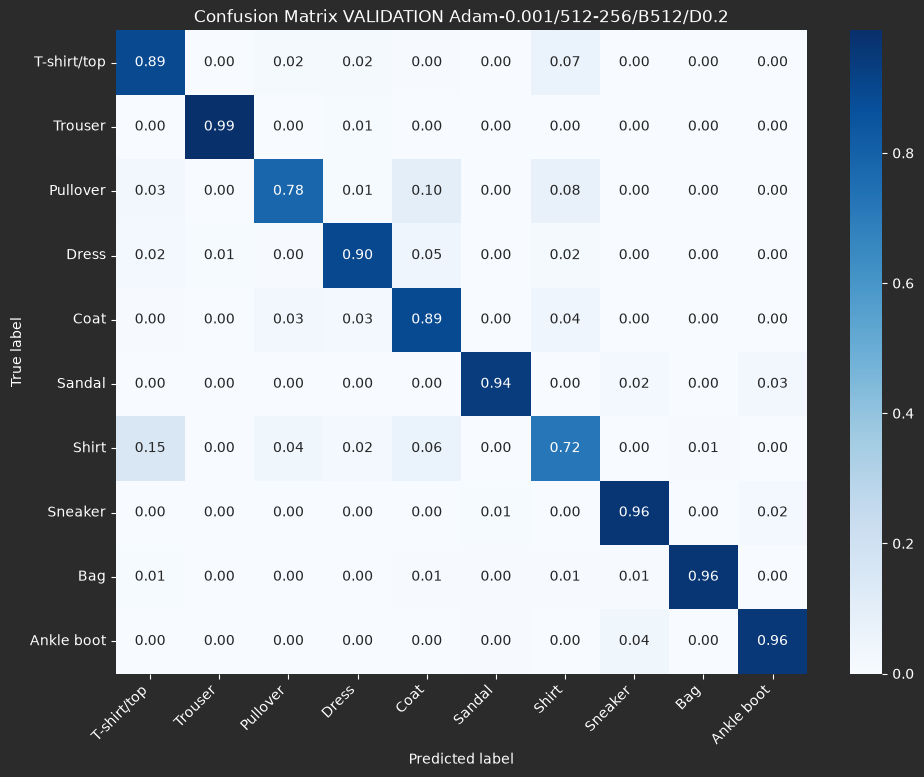

                             Train Loss Valid Loss Train Accu Valid Accu Test Accu Test Worst Class (Recall) Valid Worst Class (Recall) Test Worst Recall Value Valid Worst Recall Value TV gap Test CM Deviation Valid CM Deviation
Adam-0.001/64-32/B512/D0.2        0.314      0.334      0.886      0.882     0.874            Shirt (68.40%)             Shirt (67.09%)                   0.684                    0.671  0.004             0.321              0.292
Adam-0.001/128-64/B512/D0.2       0.233      0.299      0.915      0.893     0.886            Shirt (69.50%)             Shirt (69.99%)                   0.695                    0.700  0.022             0.270              0.241
Adam-0.001/256-128/B512/D0.2      0.187      0.301      0.931      0.898     0.891            Shirt (70.90%)             Shirt (72.99%)                   0.709                    0.730  0.033             0.259              0.225
Adam-0.001/512-256/B512/D0.2      0.156      0.313      0.941      0.898     0.891  

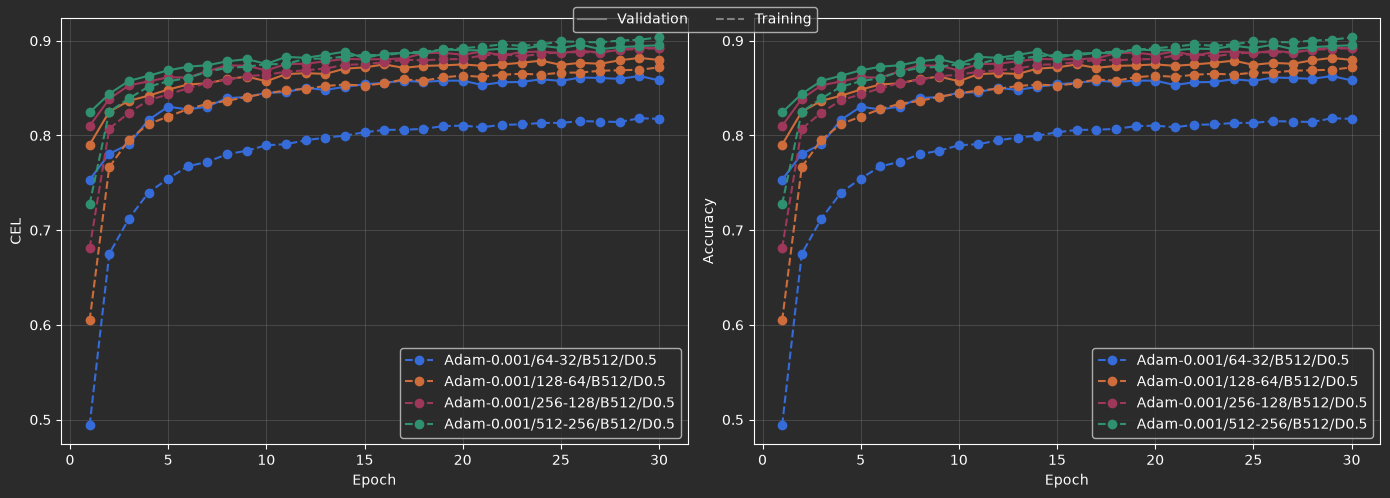

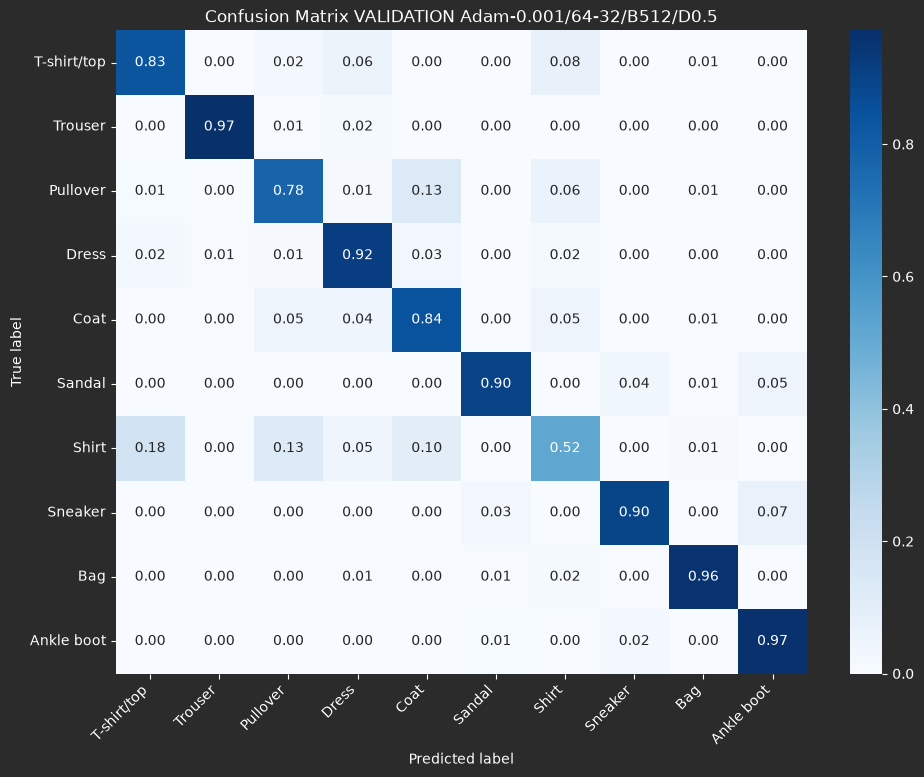

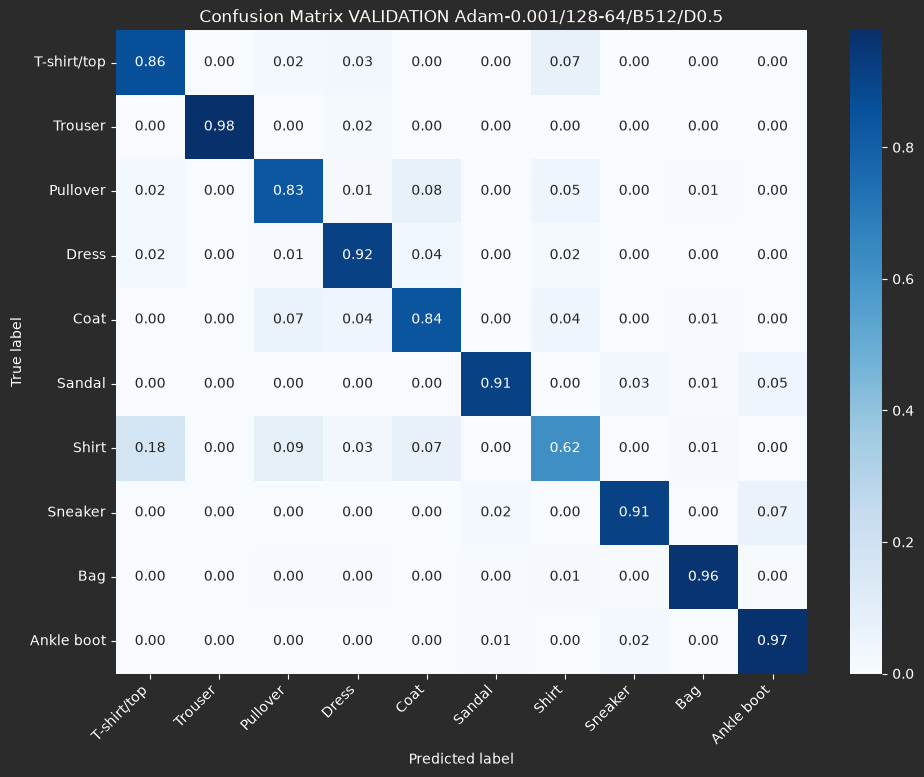

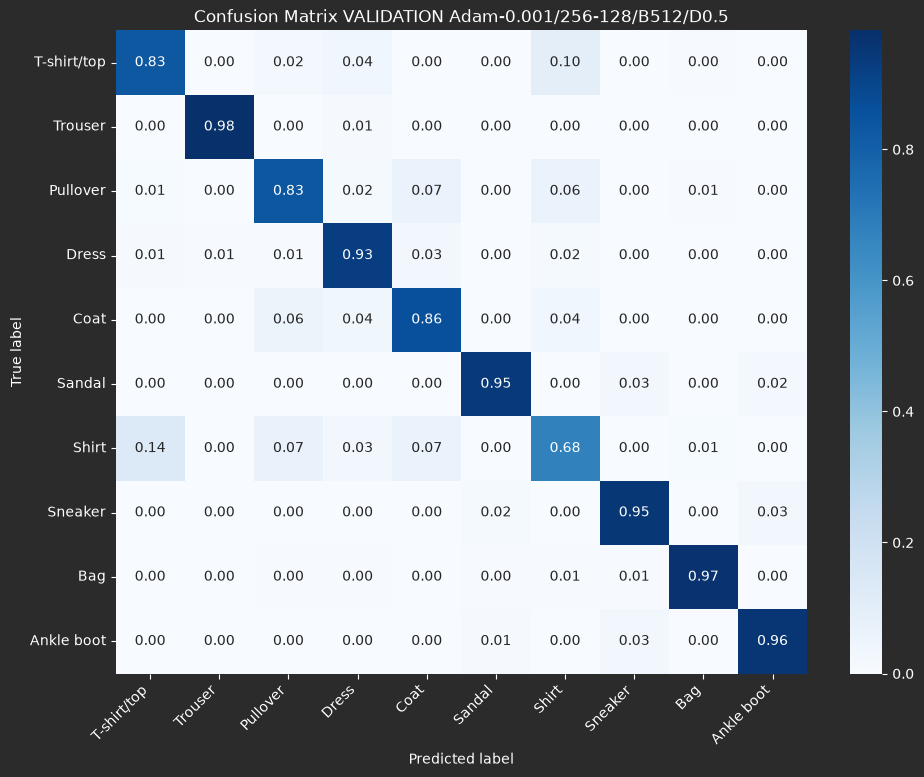

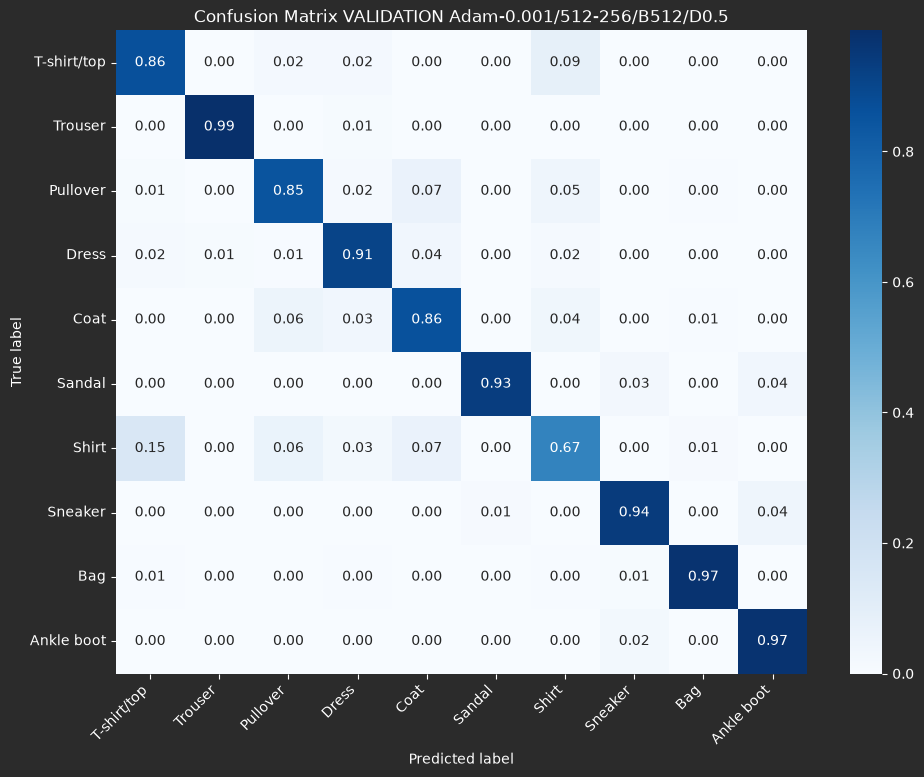

                             Train Loss Valid Loss Train Accu Valid Accu Test Accu Test Worst Class (Recall) Valid Worst Class (Recall) Test Worst Recall Value Valid Worst Recall Value TV gap Test CM Deviation Valid CM Deviation
Adam-0.001/64-32/B512/D0.5        0.518      0.403      0.818      0.858     0.850            Shirt (53.60%)             Shirt (52.37%)                   0.536                    0.524 -0.041             0.509              0.473
Adam-0.001/128-64/B512/D0.5       0.364      0.341      0.872      0.880     0.870            Shirt (59.90%)             Shirt (62.25%)                   0.599                    0.622 -0.008             0.379              0.322
Adam-0.001/256-128/B512/D0.5      0.298      0.306      0.892      0.892     0.882            Shirt (67.10%)             Shirt (67.86%)                   0.671                    0.679  0.001             0.304              0.256
Adam-0.001/512-256/B512/D0.5      0.258      0.298      0.904      0.895     0.889  

In [3]:
viewAftermath(aftermath)

import winsound
for _ in range(14):
    winsound.MessageBeep(winsound.MB_ICONEXCLAMATION)
    time.sleep(0.5)